---
title: "Langmuir-Hinshelwood-Hougen-Watson kinetics: the 1947 codimer estimation, re-run"
description: "The dual-site rate law from the people it is named after: all 18 rival mechanisms refitted from the book's own printed data, with standard errors, a 1947 worksheet slip diagnosed, a misprint in the final equation adjudicated, and the fitted law driven through a pymrm plug-flow bed."
categories: [sec:C, struct:S1, struct:S2, tier:T0, data:tier2, phase:gas, phase:gas-solid]
date: 2026-08-05
---

# Langmuir-Hinshelwood-Hougen-Watson kinetics: the 1947 codimer estimation, re-run

**Catalog ID:** `C1.1` · **Structures:** `S1` (pointwise rate algebra),
`S2` (plug flow with reaction, demonstration) · **Tier:** T0

Every catalytic rate expression of the form *kinetic term x driving force /
adsorption group* traces to one place: Hougen and Watson's *Chemical Process
Principles*, Part Three (1947), and the 1943 *Ind. Eng. Chem.* paper it grew
from. Chapter XIX does not quote the formalism: it derives it, postulates
**18 rival mechanisms** for one well-measured reaction, fits all of them to the
same printed data by least squares, and rejects sixteen on sign grounds alone.
That worked example, the hydrogenation of codimer, became the template for
every LHHW parameter estimation since.

This page re-runs the whole of that estimation from the book's own printed
numbers: the 40-run data table, the 54 rows of fitted constants, the
temperature correlation, and the final recommended equation. It reproduces the
book's arithmetic where the arithmetic is right, diagnoses a 1947 worksheet
slip where it is not, adjudicates a misprint between two printings of the same
constant, asks the modern form of the discrimination question (*can these data
actually tell the mechanisms apart?*, answered with standard errors), and then
drives the fitted law through a pymrm plug-flow bed where the mole contraction
it predicts is worth half the catalyst.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.28.10"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "C1.1-lhhw-hougen-watson"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. Packages beyond pymrm and the Colab defaults (numpy, scipy, pandas,
# matplotlib, pyyaml) are installed here with subprocess, not %pip. The
# mechanism library, eq. (q) and the plug-flow bed are in model.py.
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display
from pymrm.checks import observed_orders
from gallery_utils import Claims, cite_data, load_data, load_meta
from model import (MECH_LIN, MECH_RATE, MECH_ZEROS, RATE_D_NO_KS, RGAS, IsothermalBed, bed_wf,
                   eqq_constants, fit_rate, lin_fit, rate_eqq, rate_max_temperature, wf_quadrature)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)
claims = Claims(PAGE.split("-")[0])
BREAK = []   # (injected defect, claim, clean value, broken value, caught)


def show(styler, uuid):
    """Display a styled table with a pinned id, so two runs print the same HTML."""
    display(HTML(styler.set_uuid(uuid).to_html()))


def brk(row, metric, broken, by_failure=False):
    """One injected defect: ``broken`` is what claim ``metric`` becomes with it.
    ``by_failure`` declares that the defect leaves no solution (shown by a second route
    on the page), so a nan is the detection."""
    caught = claims.breaks(row, metric, broken, detects_by_failure=by_failure)
    BREAK.append((row, metric, claims[metric], broken, caught))
    return caught


def brk_moved(row, got, by_failure=False):
    """Break rows for the claims of ``got`` that the defect enters: a value, count or
    label that changes (a nan counts), and a bound the defect breaks. A claim the
    defect leaves where it was gets no row from this defect."""
    for n, v in got.items():
        if n not in claims.metrics:
            continue
        x = claims[n]
        if claims.metrics[n]["kind"] == "bound":
            if claims.breaks(row, n, v, detects_by_failure=by_failure):
                BREAK.append((row, n, x, v, True))
        elif isinstance(x, (bool, int, str)):
            if v != x:
                brk(row, n, v, by_failure)
        elif not (np.isfinite(v) and abs(v - x) <= 1e-9 * abs(x) + 1e-12):
            brk(row, n, v, by_failure)


def brk_study(row, study, names, *args, by_failure=False, **kw):
    """Break rows from ``study(*args, **kw)``; a study that raises (no root, no
    converged solve) records nan for every claim in ``names``."""
    try:
        got = study(*args, **kw)
    except (ValueError, RuntimeError):
        got = {n: float("nan") for n in names}
    brk_moved(row, got, by_failure)


def cols(block):
    """pH, pU, pS (atm) and the rate (lb-mol/(lb hr)) of a block of Table A."""
    return tuple(block[k].to_numpy() for k in ("pH_atm", "pU_atm", "pS_atm", "r_lbmol_per_lb_hr"))

## Background

**The source, precisely.** The document on disk is the **combined volume** of
*Chemical Process Principles*: Part One *Material and Energy Balances* (1943),
Part Two *Thermodynamics* and Part Three *Kinetics and Catalysis* (both 1947),
John Wiley & Sons, 1157 PDF pages, identified from its own title page, imprint
page and printed Contents (PDF page = book page + 16). The catalogue's
"(1943, 1947)" also names the paper O. A. Hougen and K. M. Watson published as
*Ind. Eng. Chem.* **35**, 529 (1943); the book cites it in a footnote on book
p. 906 and then develops the same treatment at much greater length, so the
paper is recorded as origin-not-consulted and everything on this page comes
from the book. The experimental data themselves are from the pilot-plant study
of Tschernitz, Bornstein, Beckmann and Hougen, *Trans. AIChE* **42**, 883
(1946), which the book reprints as its Table A; that paper was not consulted
either.

**What the formalism is.** Langmuir's isotherm gives the surface coverage of a
species adsorbing on a fixed number of active centers. Hinshelwood used it to
write rates of surface reactions between adsorbed species; Hougen and Watson
turned it into a complete estimation apparatus. The book's Chapter XIX builds
the machinery from scratch. For a **dual-site** step (a reaction needing two
adjacent centers) it derives (book p. 913) the concentration of adjacent
vacant pairs from a lattice argument: each center has $s$ equidistant
neighbours ($s = 4$ for centers on the corners of squares, $6$ for equilateral
triangles), an average vacant center has $s\,\theta_l$ vacant neighbours, and
the pair concentration is $c_{l_2} = s\,c_l^2/2L$ with the factor of one half
because the product counts every pair twice. Carrying that through the
Langmuir algebra, every limiting-step assumption lands on the same shape,

$$
r \;=\; \frac{(\text{kinetic term}) \times (\text{driving force})}
             {(\text{adsorption group})^{\,m}},
$$

with the exponent $m$ equal to the number of centers in the controlling step
and the group $1 + \sum_i K_i p_i$ collecting every adsorbed species. Which
species appear, whether hydrogen enters as $p_H$ or $\sqrt{p_H}$
(molecular or dissociated adsorption), and the exponent $m$ are the
mechanism's fingerprint, and the whole point of Chapter XIX is that these
fingerprints can be told apart, or not, from rate data.

**The modern footnote.** The adjacent-pair-site assumption at the heart of the
dual-site derivation is still argued about: Kiani & Wachs, *ACS Catalysis*
(2024), doi:10.1021/acscatal.4c02813, read alongside this page, call it "the
conundrum of pair sites": on real oxide surfaces the isolated-site picture the
algebra assumes rarely survives spectroscopic scrutiny, and the fitted $K_i$
absorb whatever the geometry actually is. That is commentary on
interpretation, not on the mathematics; the rate *forms* fitted here are the
ones in universal use regardless.

**A warning about this scan.** The PDF's native resolution is 150 ppi CCITT-G4
bilevel, the lowest of any source in this gallery, and its text layer
destroys every equation and scrambles every table. The prose text layer was
used only to *locate* material; **every numeral and every equation on this
page was read from cropped page-image enlargements at native resolution**, and
the data section below proves the transcription with the book's own printed
checksums.

## The published model

**The reaction** (Illustration 2, book pp. 943-958): vapor-phase hydrogenation
of *codimer* (mixed iso-octenes, "U" for unsaturate) to iso-octanes ("S" for
saturate) over a supported nickel catalyst,

$$\mathrm{C_8H_{16}(g) + H_2(g) \rightarrow C_8H_{18}(g)},$$

measured in a differential fixed bed at 200, 275 and 325 C and 1 to 3.5 atm,
with feed compositions from 10 to 90 mole per cent of each component. The book
establishes from its own thermodynamic calculation (Fig. 188) that the reverse
reaction is negligible below about 650 K, so all rate forms are written
forward-only.

**The 18 postulated mechanisms** (Table B, book pp. 947-949) are organised in
six groups: (I) molecularly adsorbed H2 reacting with adsorbed codimer, (II)
atomically adsorbed H2 with adsorbed codimer, (III) gas-phase codimer with
molecularly adsorbed H2, (IV) gas-phase codimer with atomically adsorbed H2,
(V) gas-phase H2 with adsorbed codimer, and (VI) the uncatalysed gas reaction,
each group split by controlling step (adsorption of either reactant, surface
reaction, desorption of product), lettered (a) through (r). Each is linearised
into

$$
R \;=\; a + b\,p_U + c\,p_S + f\,p_H
\qquad\text{or}\qquad
R \;=\; a + b\,p_U + c\,p_S + f\sqrt{p_H},
$$

where the transformed observable $R$ depends on the mechanism: $p_H/r$,
$p_U/r$, $p_Hp_U/r$, $\sqrt{p_Hp_U/r}$, $\sqrt{p_H/r}$ or
$\sqrt[3]{p_Hp_U/r}$. The constants $a,b,c,f$ are ratios of adsorption
equilibrium constants to the lumped rate constant, so **the theory requires
every constant to be positive or zero**, and that requirement, not
goodness-of-fit, is the book's discriminator (Tables D, E, F). Only two
mechanisms survive it at all three temperatures:

- **(d)** surface reaction between molecularly adsorbed H2 and adsorbed
  codimer on dual sites, $R = \sqrt{p_Hp_U/r} = a + fp_H + bp_U + cp_S$, i.e.

$$
r \;=\; \frac{\alpha K_H K_U\, p_H p_U}{(1 + K_Hp_H + K_Up_U + K_Sp_S)^2},
$$

- **(h)** the same with atomically adsorbed hydrogen,
  $r = \alpha K_H K_U p_Hp_U / (1 + \sqrt{K_Hp_H} + K_Up_U + K_Sp_S)^3$.

The book chooses (d) over (h) on two grounds it states explicitly (book
p. 952): "the experimental fit is better with mechanism d", and no
dissociation of H2 is chemically required. This page measures the first claim.

**The estimation method** (book pp. 949-952): for each mechanism, the four
constants are found by unweighted linear least squares on the transformed
variable: four normal equations in $a,b,c,f$, printed in full for mechanism
(d) at 200 C together with every summation (Table C), the eliminated 3x3
system, and the solution $a = 2.764$, $b = 1.526$, $c = 1.010$, $f = 1.129$.
The fit quality is reported as the average percentage deviation of individual
runs, printed as +-8.44 per cent.

**The temperature correlation** (book pp. 952-957): the per-temperature
constants are smoothed by least-squares straight lines on
$\log(\text{constant})$ vs $1/T$, corrected values are read off the lines,
converted to $K_U = b/a$, $K_S = c/a$, $K_H = f/a$,
$\alpha = 1/(a^2K_HK_U)$ (eq. n), and expressed as
$\ln K = -\Delta H/RT + \Delta S/R$ (Table G). The final recommended equation
(q), book p. 956, is the mechanism-(d) law with

$$
\ln K_H = \tfrac{3110}{RT} - \tfrac{8.49}{R},\quad
\ln K_U = \tfrac{940}{RT} - \tfrac{3.08}{R},\quad
\ln K_S = \tfrac{13{,}700}{RT} - \tfrac{30.96}{R}\ (\text{sic}),\quad
\ln Ek = -\tfrac{1740}{RT} + \tfrac{2.82}{R},
$$

where the *sic* marks a constant this page adjudicates: the foot of Table G
prints $\Delta S_S = -30.46$ for the same quantity eq. (q) prints as
$-30.96$.

## Parameters and assumptions

- **Units are the book's:** pressures in atm, rates in lb-mol/(lb catalyst hr),
  $R = 1.987$ cal/(g-mol K), and the era's absolute-temperature convention
  $T(\mathrm{K}) = t(\mathrm{C}) + 273.16$.
- **Forward-only kinetics.** The book's own equilibrium calculation (Fig. 188)
  makes the reverse term negligible below about 650 K; the hottest data are at
  598 K. Eq. (q)'s driving force $p_Hp_U - p_S/K$ is therefore evaluated
  without the $p_S/K$ term everywhere on this page, which is exactly what the
  book does in Tables B to G ("the terms involving the reverse reaction drop out
  because of the high equilibrium constant", book p. 947).
- **Differential-bed rates.** Each Table A rate is a finite-difference rate at
  the run's *average* partial pressures; the book states the beds were operated
  at mass velocities where interphase gradients are negligible and the surface
  activities equal the bulk ones. This page takes that at face value: it is
  the source's own experimental design claim.
- **Unweighted least squares on the transformed variable is the book's method**
  and is reproduced as such. Where this page fits in rate space instead, the
  residual is relative ($\Delta r / r$), which matches the book's own
  percentage-deviation metric.
- **Standard errors.** A difference between two mechanisms' mean absolute
  deviations is a paired difference over the same runs; its standard error is
  the sample standard deviation of the per-run differences over $\sqrt{n}$, per
  temperature, combined in quadrature for the mean over the three temperatures.
  A gap is called resolved only beyond `Z_RESOLVED` standard errors (set below).
- **Reactor demonstration conditions** are chosen inside the fitted range
  (200 C, 3.5 atm); the book's Chapter XXI poses exactly this integration as
  its Problem 1 but at 250 to 350 F, *outside* the 200 to 325 C range of
  eq. (q)'s constants, and prints no answer, so the demonstration stays at
  200 C and is labelled a demonstration, not a validation.

In [3]:
# Parameters, with unit and source.
T_OF = {200: 473.16, 275: 548.16, 325: 598.16}   # K, the book's T = t + 273.16
TEMPS = (200, 275, 325)                          # C, the three blocks of Table A
CLEAN_RHS = 0.03         # a printed Table D/E/F row is "consistent" below this implied-sum deviation (chosen)
THR_SIGN = 0.05          # sign test: a constant is nonzero above this fraction of the fit's largest (chosen)
THR_SWEEP = (0.01, 0.02, 0.05, 0.10)             # thresholds swept for the sign test
Z_RESOLVED = 2.0         # a paired gap is "resolved" beyond this many standard errors (chosen)
P_BED = 3.5              # atm, total pressure of the bed demonstration (inside Table A's 1 to 3.5 atm)
FEED = (1.0, 1.4, 0.0)   # U, H2, S per mole of U fed: hydrogen 40 % over stoichiometric (Chap. XXI, Problem 1)
NU = (-1.0, -1.0, 1.0)   # U + H2 -> S
X_TARGET = 0.998         # 99.8 % hydrogenation (Chap. XXI, Problem 1)
NS_BED = (100, 200, 400, 800, 1600)              # cells of the grid ladder

## The data

Six datasets, all transcribed from native-resolution page renders of the book
(150 ppi CCITT-G4; crops enlarged 4x nearest-neighbour; the text layer was
never trusted for a single digit):

| file | book source | what it is |
|---|---|---|
| `tableA-rates` | Table A, pp. 944-945 | the 40 measured runs (12 at 200 C, 13 at 275, 15 at 325): average $p_H, p_U, p_S$ and rate $r$ |
| `tableC-mechd-200C` | Table C, pp. 950-951 | the book's own per-run fit evaluation at 200 C (last five columns) |
| `tablesDEF-constants` | Tables D/E/F, pp. 953-955 | the book's fitted $a,b,c,f$ for all 18 mechanisms x 3 temperatures, with the printed verdicts |
| `tableG-summary` | Table G, p. 957 | experimental and corrected constants, and the derived $K$'s |
| `eqq-thermo` | eq. (q) p. 956 + Table G foot p. 957 | $\Delta H$, $\Delta S$, $A$, $B$, **both** printings where they disagree |
| `printed-intermediates` | pp. 945-952 | the 13 normal-equation sums at 200 C, Table C's printed fit quality, the run 3c specimen calculation |

**Everything here is fit data.** Every constant in the book was fitted to these
same 40 runs; no held-out measurement exists anywhere in the source. What this
page validates is therefore the *reproduction of the estimation* (and the
internal consistency the book's printed intermediates make checkable), never
the predictive power of the rate law on unseen data; the fit/test labelling in
`meta.yaml` says the same thing.

**The transcription is provable for the 200 C block**, because the book prints
its own sums: the normal equations (f) to (i) on book p. 952 contain thirteen
summations. The checksum cell below reproduces every one. The 275 and 325
blocks have no printed sums; their transcription is checked instead by
reproducing Tables E and F. No other page's dataset is loaded, and no figure
was digitised: the two figures of Illustration 2 (Fig. 188a and Fig. 189) plot
quantities whose defining numbers are all printed, so everything figure-shaped
on this page is *computed* from printed constants. The only content scoped out
for that reason is the Johanson-Watson toluene example on book pp. 959-961,
whose constants derive from conversion *curves* (Figs. 182-185), and a
different case in any event.

In [4]:
A = load_data("hougen-watson-1947-tableA-rates.csv", page=PAGE)
TC = load_data("hougen-watson-1947-tableC-mechd-200C.csv", page=PAGE)
DEF = load_data("hougen-watson-1947-tablesDEF-constants.csv", page=PAGE)
DEF_STR = load_data("hougen-watson-1947-tablesDEF-constants.csv", page=PAGE, dtype=str)   # the printed digits
TG = load_data("hougen-watson-1947-tableG-summary.csv", page=PAGE).set_index("quantity")
TH = load_data("hougen-watson-1947-eqq-thermo.csv", page=PAGE).set_index("name")["value"]
PRINTED = load_data("hougen-watson-1947-printed-intermediates.csv", page=PAGE,
                    dtype=str).set_index("name")["printed"]     # strings: the printed digits


def pv(name):
    """A printed intermediate as a number."""
    return float(PRINTED[name])


def half_unit(name):
    """Half a unit of the last printed digit of a printed intermediate."""
    s = PRINTED[name]
    return 0.5 * 10.0 ** -(len(s.split(".")[1]) if "." in s else 0)


print(cite_data(load_meta("hougen-watson-1947-tableA-rates.csv", page=PAGE)))
print("runs per temperature: " + ", ".join(f"{t} C: {int((A.temp_C == t).sum())}" for t in TEMPS))
A.head(4)

Hougen, O. A.; Watson, K. M. (1947) — John Wiley & Sons, New York; Chapman & Hall, London. Chap. XIX, Illustration 2, Table A, book pp. 944-945 — table
runs per temperature: 200 C: 12, 275 C: 13, 325 C: 15


,run,temp_C,pi_atm,pH_atm,pU_atm,pS_atm,r_lbmol_per_lb_hr
0,1d,200,1.09,0.482,0.100,0.508,0.00353
1,3c,200,3.50,2.459,0.527,0.515,0.02500
2,3d,200,3.49,2.450,0.530,0.515,0.03200
3,10a,200,3.51,0.477,0.494,2.538,0.00553


In [5]:
# Reproduce the book's specimen conversion of raw measurements into a Table A
# row (run 3c, book pp. 945-946): refractometry -> conversion -> rate.
def specimen(factor=None):
    """The run 3c arithmetic; ``factor`` replaces the printed per cent per unit index."""
    f = pv("run3c per cent per unit index") if factor is None else factor
    liq = pv("run3c liquid ml/hr") * pv("run3c specific gravity") / (
        pv("run3c molecular weight") * pv("run3c g per lb"))
    pct = f * pv("run3c refractive index difference")
    conv = 0.01 * liq * pct
    rate = conv / pv("run3c catalyst lb")
    r_tab = float(A.loc[A.run == "3c", "r_lbmol_per_lb_hr"].iloc[0])
    return {"liq": liq, "pct": pct, "conv": conv, "rate": rate, "r_tab": r_tab,
            "run3c_specimen_rate_vs_tableA_rel": abs(r_tab - rate) / r_tab}


SP = specimen()
claims.value("run3c_specimen_rate_vs_tableA_rel", SP["run3c_specimen_rate_vs_tableA_rel"], rtol=0.05)
display(Markdown(f"""
| step | recomputed | book prints |
|---|---|---|
| liquid leaving, lb-mol/hr | {SP['liq']:.5f} | {PRINTED['run3c liquid lb-mol/hr']} |
| composition change, % | {SP['pct']:.2f} | {PRINTED['run3c per cent change']} |
| conversion, lb-mol/hr | {SP['conv']:.6f} | {PRINTED['run3c conversion lb-mol/hr']} |
| rate, lb-mol/(hr lb) | {SP['rate']:.5f} | {PRINTED['run3c rate']} |

Table A prints **{SP['r_tab']}** for run 3c against the specimen's
{SP['rate']:.5f}, a {100 * claims['run3c_specimen_rate_vs_tableA_rel']:.1f} % difference the
book does not explain; the specimen is worked at the run's actual average
temperature of 200.5 C while Table A is the 200 C block, so a normalisation
of that size is plausible, but it is the book's, not ours. The blank-test
correction the book describes (1 to 5 % of the catalysed rate, at 325 C only)
is already in the printed rates.
"""))


| step | recomputed | book prints |
|---|---|---|
| liquid leaving, lb-mol/hr | 0.01671 | 0.01671 |
| composition change, % | 6.54 | 6.54 |
| conversion, lb-mol/hr | 0.001093 | 0.001093 |
| rate, lb-mol/(hr lb) | 0.02483 | 0.02484 |

Table A prints **0.025** for run 3c against the specimen's
0.02483, a 0.7 % difference the
book does not explain; the specimen is worked at the run's actual average
temperature of 200.5 C while Table A is the 200 C block, so a normalisation
of that size is plausible, but it is the book's, not ours. The blank-test
correction the book describes (1 to 5 % of the catalysed rate, at 325 C only)
is already in the printed rates.


In [6]:
# Prove the 200 C transcription against the book's own printed sums. Book p. 952
# prints the four normal equations for mechanism (d) with every coefficient. The
# R-dependent sums are formed with Table C's printed R column, the values the
# book summed.
SUMS = ["Sum pH", "Sum pU", "Sum pS", "Sum pH2", "Sum pU2", "Sum pS2", "Sum pHpU", "Sum pHpS",
        "Sum pUpS", "Sum R", "Sum RpH", "Sum RpU", "Sum RpS"]
LIN, PROD, RSUM = SUMS[:3], SUMS[3:9], SUMS[9:]


def checksums(block=None, tc=None):
    """Recomputed sums of the 200 C block against the printed ones; ``block`` replaces
    the block, ``tc`` Table C."""
    d = A[A.temp_C == 200] if block is None else block
    tc = TC if tc is None else tc
    H, U, S, r = cols(d)
    R = tc.set_index("run").loc[d.run, "R_exp_printed"].to_numpy()
    mine = dict(zip(SUMS, [H.sum(), U.sum(), S.sum(), (H**2).sum(), (U**2).sum(), (S**2).sum(),
                           (H * U).sum(), (H * S).sum(), (U * S).sum(), R.sum(), (R * H).sum(),
                           (R * U).sum(), (R * S).sum()]))
    halves = {k: abs(mine[k] - pv(k)) / half_unit(k) for k in SUMS}
    return {"mine": mine, "halves": halves,
            "tableA_linear_psum_max_abs": max(abs(mine[k] - pv(k)) for k in LIN),
            "tableA_product_psum_max_rel": max(abs(mine[k] - pv(k)) / pv(k) for k in PROD),
            "tableA_product_psum_max_half_units": max(halves[k] for k in PROD),
            "tableA_Rsum_check_max_rel": max(abs(mine[k] - pv(k)) / pv(k) for k in RSUM),
            "tableC_Rexp_vs_recomputed_max_abs": float(np.max(np.abs(R - np.sqrt(H * U / r))))}


CK = checksums()
df = pd.DataFrame([(k, PRINTED[k], CK["mine"][k], CK["halves"][k]) for k in SUMS],
                  columns=["sum", "printed", "recomputed", "|gap| in half-units of the last printed digit"])
show(df.style.format({"recomputed": "{:.4f}", df.columns[-1]: "{:.2g}"}).hide(axis="index"), "c1101")
claims.bound("tableA_linear_psum_max_abs", CK["tableA_linear_psum_max_abs"], max=1e-9, basis="chosen",
             note="sums of three-decimal entries equal a three-decimal printed sum to round-off when "
                  "every digit is transcribed right; one wrong digit moves it by 1e-3 or more")
claims.bound("tableA_product_psum_max_half_units", CK["tableA_product_psum_max_half_units"], max=1.0,
             basis="chosen", note="within half a unit of the printed last digit: the book's rounding")
claims.value("tableA_product_psum_max_rel", CK["tableA_product_psum_max_rel"], rtol=0.05)
claims.value("tableA_Rsum_check_max_rel", CK["tableA_Rsum_check_max_rel"], rtol=0.05)
claims.value("tableC_Rexp_vs_recomputed_max_abs", CK["tableC_Rexp_vs_recomputed_max_abs"], rtol=0.05)

display(Markdown(f"""
The three linear pressure sums agree with the printed normal equations to
at most 1e-9 absolute (here {CK['tableA_linear_psum_max_abs']:.0e}), that is digit for digit:
those three are closed by the transcription alone, so the 200 C pressure
columns are proven. The six product sums lie within
**{CK['tableA_product_psum_max_half_units']:.2f}** half-units of the printed last digit
(at most {CK['tableA_product_psum_max_rel']:.1e} relative), which is the book's own
rounding of each sum (Table C prints $\\Sigma p_U^2$ as {PRINTED['Sum pU2 (Table C)']} where the
normal equation uses {PRINTED['Sum pU2']}: the book disagrees with itself by one unit). The
four $R$-dependent sums, formed with Table C's printed $R$ column (the values the book summed),
agree to **{CK['tableA_Rsum_check_max_rel']:.1e}** relative, the rounding of the per-run
products. The printed $R$ itself differs from $\\sqrt{{p_Hp_U/r}}$ recomputed from Table A by up
to {CK['tableC_Rexp_vs_recomputed_max_abs']:.3f}, {CK['tableC_Rexp_vs_recomputed_max_abs'] / 0.01:.1f} units of
its second decimal: the book's $R$ column was not computed from Table A's printed digits alone.

*What this cannot catch:* a slip in the 275 or 325 blocks, which have no
printed sums; those blocks are checked instead by reproducing Tables E and F
below.
"""))

sum,printed,recomputed,|gap| in half-units of the last printed digit
Sum pH,9.129,9.1290,0
Sum pU,12.178,12.1780,3.6e-12
Sum pS,7.531,7.5310,1.8e-12
Sum pH2,13.960,13.9602,0.32
Sum pU2,21.682,21.6816,0.8
Sum pS2,9.125,9.1252,0.47
Sum pHpU,7.253,7.2528,0.37
Sum pHpS,5.442,5.4415,0.93
Sum pUpS,5.588,5.5881,0.29
Sum R,69.660,69.6600,2.8e-11



The three linear pressure sums agree with the printed normal equations to
at most 1e-9 absolute (here 2e-15), that is digit for digit:
those three are closed by the transcription alone, so the 200 C pressure
columns are proven. The six product sums lie within
**0.93** half-units of the printed last digit
(at most 8.5e-05 relative), which is the book's own
rounding of each sum (Table C prints $\Sigma p_U^2$ as 21.681 where the
normal equation uses 21.682: the book disagrees with itself by one unit). The
four $R$-dependent sums, formed with Table C's printed $R$ column (the values the book summed),
agree to **3.9e-05** relative, the rounding of the per-run
products. The printed $R$ itself differs from $\sqrt{p_Hp_U/r}$ recomputed from Table A by up
to 0.028, 2.8 units of
its second decimal: the book's $R$ column was not computed from Table A's printed digits alone.

*What this cannot catch:* a slip in the 275 or 325 blocks, which have no
printed sums; those blocks are checked instead by reproducing Tables E and F
below.


## PyMRM implementation

The LHHW algebra itself is pointwise (no operator, no grid), so the pymrm
content here is the bed of Section 5; the rest is NumPy and SciPy, labelled as
such. `model.py` holds:

1. **the rate-law library**: all 18 mechanism forms and the linearised
   least-squares engine, in the shape downstream pages (`C2.3`, `C2.4`,
   `C2.10`, `C2.19`, all LHHW instances) can import;
2. **the rate-space fit** (`scipy.optimize.least_squares`), returning the solver
   status, the gradient at the solution and per-parameter standard errors;
3. **eq. (q)** and the temperature of its rate maximum, the root of the analytic
   derivative of $\ln r$ with `pymrm.checks.find_roots`;
4. **a plug-flow bed** of the fitted law, an `S2` pymrm problem: molar flows
   $N_i(w)$ (shape `(n, 3)`, space first, species last) on a grid in the
   catalyst-mass coordinate $w = W/F_{U0}$, `construct_convflux_upwind` and
   `construct_div` (assembled once) for $\mathrm{d}N_i/\mathrm{d}w = \nu_i r$,
   a `NumJac((n, 3))` stencil (the rate couples the three species pointwise),
   and `newton` with its `success` checked. The rate is nonlinear in the flows,
   so the steady problem needs Newton. The reaction removes one mole per mole
   converted, so the partial pressures are built from the *local* total flow.

Boundary conditions follow the outward-normal convention $a\,\partial N/\partial n
+ b\,N = d$: at the inlet $w = 0$ the feed fixes the face value, $N_i = N_{i,0}$
(`{a: 0, b: 1, d: N_feed}`); the outlet $w = W$ is a pure convection outflow,
`{"outflow": True}`, whose face carries the adjacent cell's value, and the outlet
flows are read with `compute_boundary_values` under that condition. `nu=0` in
`construct_div` because the coordinate is catalyst mass, not a curved geometry.
The bed length that reaches the target conversion is a root of the outlet
conversion in the bed length (`find_roots`), not a read-off of a profile.

In [7]:
print("mechanism library:", len(MECH_LIN), "linearisations,", len(MECH_RATE), "rate laws")

mechanism library: 18 linearisations, 18 rate laws


## Results

### 1. The book's own estimation at 200 C, re-run two ways

Two routes to the mechanism-(d) constants, sharing no inputs beyond the model
form: (i) least squares on the *transcribed data*; (ii) direct solution of the
*normal equations exactly as the book prints them* (book p. 952, eqs. f-i).
The second route never touches this page's transcription of Table A, so their
agreement is a second, independent computation of the headline constants.

In [8]:
# Mechanism (d) at 200 C: the data route, the printed-normal-equations route and
# the printed solution (Table G's experimental row at 200 C); then the book's
# Table C fit-quality arithmetic and the run 25a cell.
BOOK_D200 = np.array([TG.loc[f"{k}_experimental", "val_200C"] for k in "abcf"], dtype=float)


def mechd_study(block=None, tc=None, book=None):
    """``block`` replaces Table A's 200 C block, ``tc`` Table C, ``book`` the printed solution."""
    d = A[A.temp_C == 200] if block is None else block
    book = BOOK_D200 if book is None else book
    tc = TC if tc is None else tc
    H, U, S, r = cols(d)
    coef, X, R = lin_fit("d", H, U, S, r)
    s = {k: pv(k) for k in SUMS}
    n_runs = float(len(tc))       # the printed system's first coefficient is the run count
    M = np.array([[n_runs, s["Sum pU"], s["Sum pS"], s["Sum pH"]],
                  [s["Sum pH"], s["Sum pHpU"], s["Sum pHpS"], s["Sum pH2"]],
                  [s["Sum pU"], s["Sum pU2"], s["Sum pUpS"], s["Sum pHpU"]],
                  [s["Sum pS"], s["Sum pUpS"], s["Sum pS2"], s["Sum pHpS"]]])
    rhs = np.array([s["Sum R"], s["Sum RpH"], s["Sum RpU"], s["Sum RpS"]])
    coef_sums = np.linalg.solve(M, rhs)
    R_calc = X @ coef
    delta = R_calc - R
    i25 = int(np.where(d.run.to_numpy() == "25a")[0][0])
    row25 = tc.set_index("run").loc["25a"]
    consistent = float(row25.R_exp_printed + row25.delta_printed)
    gap25 = abs(float(row25.R_calc_printed) - consistent)
    rounding25 = 3 * 0.005          # R_exp, delta and R_calc are each printed to 2 decimals
    others = np.arange(len(d)) != i25
    rc_printed = tc.set_index("run").loc[d.run, "R_calc_printed"].to_numpy()
    tc_cols = max(abs(tc.delta_sq_printed.sum() - pv("Sum delta2")) / half_unit("Sum delta2"),
                  abs(np.abs(tc.pct_delta_printed).mean() - pv("avg abs pct")) / half_unit("avg abs pct"))
    return {"coef": coef, "coef_sums": coef_sums, "R_calc": R_calc, "i25": i25, "consistent25": consistent,
            "sum_dsq": float(np.sum(delta**2)), "sum_dsq_book": float(tc.delta_sq_printed.sum()),
            "avg_pct_book": float(np.abs(tc.pct_delta_printed).mean()),
            "mechd_200C_vs_printed_max_rel": float(np.max(np.abs(coef - book) / book)),
            "mechd_200C_two_routes_max_rel": float(np.max(np.abs(coef - coef_sums) / coef_sums)),
            "mechd_printed_solution_vs_own_system_max_rel": float(np.max(np.abs(coef_sums - book) / book)),
            "tableC_sum_delta_sq_rel_dev": abs(float(np.sum(delta**2)) - pv("Sum delta2")) / pv("Sum delta2"),
            "tableC_avg_abs_pct": float(np.mean(np.abs(100 * delta / R))),
            "tableC_printed_columns_max_half_units": float(tc_cols),
            "tableC_25a_printed_minus_consistent": gap25,
            "tableC_25a_gap_over_rounding": gap25 / rounding25,
            "tableC_other_Rcalc_worst_abs": float(np.max(np.abs(R_calc[others] - rc_printed[others])))}


MD = mechd_study()
tbl = pd.DataFrame({"printed (book p. 952)": BOOK_D200, "route i: from transcribed data": MD["coef"],
                    "route ii: from printed sums": MD["coef_sums"]}, index=["a", "b", "c", "f"])
show(tbl.style.format("{:.4f}"), "c1102")
for name in ("mechd_200C_vs_printed_max_rel", "mechd_200C_two_routes_max_rel",
             "mechd_printed_solution_vs_own_system_max_rel", "tableC_sum_delta_sq_rel_dev",
             "tableC_avg_abs_pct", "tableC_25a_printed_minus_consistent", "tableC_25a_gap_over_rounding",
             "tableC_other_Rcalc_worst_abs"):
    claims.value(name, MD[name], rtol=0.05)
claims.bound("tableC_printed_columns_max_half_units", MD["tableC_printed_columns_max_half_units"], max=1.0,
             basis="chosen", note="the printed columns sum to the printed totals within half a unit of their last digit")

display(Markdown(f"""
Both routes land on the printed constants: worst relative deviation
**{claims['mechd_200C_vs_printed_max_rel']:.2%}** (route i against the printed solution) and
**{claims['mechd_200C_two_routes_max_rel']:.2%}** between the two routes. The
printed solution itself sits {claims['mechd_printed_solution_vs_own_system_max_rel']:.2%} from
the exact solution of its own printed system, the residue of determinant
elimination by hand.

The book's fit-quality numbers reproduce the same way: recomputed at full
precision, $\\Sigma\\delta^2$ = **{MD['sum_dsq']:.4f}** ({claims['tableC_sum_delta_sq_rel_dev']:.1e}
relative from the printed {PRINTED['Sum delta2']}) and the average absolute percentage deviation is
**{claims['tableC_avg_abs_pct']:.2f} %** against the printed +-{PRINTED['avg abs pct']}; summing the
book's own printed per-run columns gives {MD['sum_dsq_book']:.3f} and {MD['avg_pct_book']:.2f}, within
{claims['tableC_printed_columns_max_half_units']:.2f} half-units of the printed totals.

**One printed cell is wrong, and its own row proves it.** Run 25a's
$R_{{calc}}$ prints {TC.set_index('run').loc['25a', 'R_calc_printed']:.2f}, but the same row's
$\\delta$ = {TC.set_index('run').loc['25a', 'delta_printed']:.2f},
$\\delta^2$ = {TC.set_index('run').loc['25a', 'delta_sq_printed']:.3f} and
{TC.set_index('run').loc['25a', 'pct_delta_printed']:.2f} % all require
$R_{{calc}}$ = {MD['consistent25']:.2f}, and the recomputed value is
{MD['R_calc'][MD['i25']]:.2f}. The printed value is off by
**{claims['tableC_25a_printed_minus_consistent']:.2f}**, {claims['tableC_25a_gap_over_rounding']:.0f}
times the largest rounding of the three printed two-decimal inputs: a digit slip in one
cell, and the downstream columns were computed from the correct value. Worst
deviation of any *other* printed $R_{{calc}}$ from recomputation:
{claims['tableC_other_Rcalc_worst_abs']:.3f}. Reported, not repaired.
"""))

,printed (book p. 952),route i: from transcribed data,route ii: from printed sums
a,2.7640,2.7677,2.7648
b,1.5260,1.5277,1.5250
c,1.0100,1.0158,1.0095
f,1.1290,1.1346,1.1292



Both routes land on the printed constants: worst relative deviation
**0.58%** (route i against the printed solution) and
**0.63%** between the two routes. The
printed solution itself sits 0.07% from
the exact solution of its own printed system, the residue of determinant
elimination by hand.

The book's fit-quality numbers reproduce the same way: recomputed at full
precision, $\Sigma\delta^2$ = **3.0061** (1.4e-03
relative from the printed 3.002) and the average absolute percentage deviation is
**8.42 %** against the printed +-8.44; summing the
book's own printed per-run columns gives 3.002 and 8.44, within
0.17 half-units of the printed totals.

**One printed cell is wrong, and its own row proves it.** Run 25a's
$R_{calc}$ prints 5.40, but the same row's
$\delta$ = -0.40,
$\delta^2$ = 0.160 and
-6.35 % all require
$R_{calc}$ = 5.90, and the recomputed value is
5.92. The printed value is off by
**0.50**, 33
times the largest rounding of the three printed two-decimal inputs: a digit slip in one
cell, and the downstream columns were computed from the correct value. Worst
deviation of any *other* printed $R_{calc}$ from recomputation:
0.026. Reported, not repaired.


### 2. Tables D, E, F re-fitted, and a 1947 worksheet slip

The book prints fitted constants for all 18 mechanisms at all three
temperatures. Re-fitting every one from Table A and asking, for each printed
row, *what normal-equation right-hand side would have produced it* separates
three populations: rows that reproduce (hand-rounding only), rows corrupted by
an identifiable single worksheet entry, and one row that stays unexplained.

In [9]:
# Re-fit all 54 rows; classify each printed row by the right-hand side it implies.
# For a printed row x, rhs_needed = G @ x (G the exact normal matrix from the
# transcribed data); a single corrupted summation shows as a single deviant element.
FAMILY = {}
for m, key in MECH_LIN.items():
    FAMILY.setdefault(key, []).append(m)     # mechanisms sharing one regression


# the three duplicate rows: (T, constant, first member of the family) -> claim name
DUP_CLAIM = {(275, "c", "c"): "DEF_dup_c275_gap_over_halfunit", (325, "a", "b"): "DEF_dup_bq325_gap_over_halfunit",
             (325, "a", "c"): "DEF_dup_c325_gap_over_halfunit"}


def def_study(data=None, h_basis=None, element=2, table=None, unit_factor=1.0):
    """``data`` replaces Table A, ``h_basis`` mechanism h's hydrogen basis, ``element``
    the summation the 200 C anomaly is attributed to (2 = Sum R pS), ``table`` Tables D/E/F,
    ``unit_factor`` the printing unit of the constants in units of the printed last digit (1 = as printed)."""
    AA = A if data is None else data
    D = DEF if table is None else table
    recs, diag = [], {}
    for T in TEMPS:
        H, U, S, r = cols(AA[AA.temp_C == T])
        for mech in MECH_LIN:
            coef, X, R = lin_fit(mech, H, U, S, r, basis=h_basis if mech == "h" else None)
            G, rhs = X.T @ X, X.T @ R
            row = D[(D.mechanism == mech) & (D.temp_C == T)].iloc[0]
            printed = np.array([row.a, row.b, row.c, row.f], dtype=float)
            rel = (G @ printed - rhs) / rhs
            recs.append((mech, T, *printed, *coef, float(np.max(np.abs(rel)))))
            diag[(mech, T)] = (coef, rel, G, rhs, printed)
    rep = pd.DataFrame(recs, columns=["mech", "T_C", "a_print", "b_print", "c_print", "f_print",
                                      "a_fit", "b_fit", "c_fit", "f_fit", "max_rel_rhs"])
    clean = rep[rep.max_rel_rhs < CLEAN_RHS]
    implied = {m: float((diag[(m, 200)][2] @ diag[(m, 200)][4])[element]) for m in ("c", "g")}
    sub = {}
    for m in ("c", "g"):
        coef, rel, G, rhs, printed = diag[(m, 200)]
        rhs_bad = rhs.copy()
        rhs_bad[element] = implied["c"]
        sub[m] = float(np.max(np.abs(np.linalg.solve(G, rhs_bad) - printed) / np.abs(printed)))
    # printed duplicates: one regression printed with two values of one constant. Each
    # value is judged by the implied-sum test on the family's row: the largest relative
    # deviation over the summations that stay below CLEAN_RHS for both values.
    dups, dup_ratio = [], {name: np.nan for name in DUP_CLAIM.values()}
    for key, members in FAMILY.items():
        for T in TEMPS:
            for j, k in enumerate("abcf"):
                vals = {}
                for m in members:
                    vals.setdefault(float(diag[(m, T)][4][j]), []).append(m)
                if len(vals) < 2:
                    continue
                coef, rel, G, rhs, printed = diag[(members[0], T)]
                devs = {}
                for v in vals:
                    x = printed.copy()
                    x[j] = v
                    devs[v] = (G @ x - rhs) / rhs
                ok = np.all([np.abs(d) < CLEAN_RHS for d in devs.values()], axis=0)
                ok = ok if ok.any() else np.ones_like(ok)     # every summation deviant: judge on all
                score = {v: float(np.max(np.abs(d[ok]))) for v, d in devs.items()}
                # the largest shift of the judged sums when the coefficient moves by half a printed unit
                strs = DEF_STR[(DEF_STR.temp_C.astype(float) == T)
                               & DEF_STR.mechanism.isin([m for ms in vals.values() for m in ms])][k]
                half = unit_factor * max(0.5 * 10.0 ** -(len(x.split(".")[1]) if "." in x else 0) for x in strs)
                shift = float(np.max(np.abs(G[ok, j]) * half / np.abs(rhs[ok])))
                ratio = abs(max(score.values()) - min(score.values())) / shift
                name = DUP_CLAIM.get((T, k, members[0]))
                if name:
                    dup_ratio[name] = ratio
                dups.append((T, k, vals, score, min(score, key=score.get), ratio, name))
    return {"rep": rep, "diag": diag, "implied": implied, "dups": dups,
            "DEF_clean_row_count": int(len(clean)),
            "clean_margin": float(np.min(np.abs(rep.max_rel_rhs - CLEAN_RHS)) / CLEAN_RHS),
            "DEF_clean_rows_worst_rel_rhs": float(clean.max_rel_rhs.max()),
            "DEF_corrupted_sum_two_witness_gap_rel": abs(implied["c"] - implied["g"]) / abs(implied["c"]),
            "DEF_substituted_c_row_rel": sub["c"], "DEF_substituted_g_row_rel": sub["g"],
            "DEF_implied_sum_RpS_c_row": implied["c"], "DEF_data_sum_RpS": float(diag[("c", 200)][3][element]),
            "DEF_h200_sum_RpS_rel": float(diag[("h", 200)][1][2]),
            "DEF_el275_sum_RpU_rel": float(diag[("e", 275)][1][1]),
            "DEF_f275_sum_RpU_rel": float(diag[("f", 275)][1][1]),
            "DEF_bq325_sum_RpH_rel": float(diag[("b", 325)][1][3]),
            "DEF_gm275_worst_rel": float(np.max(np.abs(diag[("g", 275)][1]))),
            "DEF_duplicate_inconsistencies": len(dups), **dup_ratio}


DS = def_study()
rep, diag = DS["rep"], DS["diag"]
claims.count("DEF_clean_row_count", rep.max_rel_rhs, CLEAN_RHS, above=False, min_margin=0.1,
             note="printed rows whose implied normal-equation sums all lie within CLEAN_RHS of the data's")
for name in ("DEF_clean_rows_worst_rel_rhs", "DEF_corrupted_sum_two_witness_gap_rel", "DEF_substituted_c_row_rel",
             "DEF_substituted_g_row_rel", "DEF_implied_sum_RpS_c_row", "DEF_data_sum_RpS", "DEF_h200_sum_RpS_rel",
             "DEF_el275_sum_RpU_rel", "DEF_f275_sum_RpU_rel", "DEF_bq325_sum_RpH_rel", "DEF_gm275_worst_rel"):
    claims.value(name, DS[name], rtol=0.05)
claims.exact("DEF_duplicate_inconsistencies", DS["DEF_duplicate_inconsistencies"])
for name in DUP_CLAIM.values():
    claims.value(name, DS[name], rtol=0.05)
alt = def_study(element=1)      # the same diagnosis attributed to Sum R pU
dirty = rep[rep.max_rel_rhs >= CLEAN_RHS].drop_duplicates(subset=["T_C", "max_rel_rhs"])
display(Markdown(f"**{claims['DEF_clean_row_count']} of {len(rep)} printed rows** are consistent with the "
                 f"transcribed data to better than {CLEAN_RHS:.0%} in every implied summation (worst "
                 f"{claims['DEF_clean_rows_worst_rel_rhs']:.1%}, the book's hand rounding; the nearest row to "
                 f"the threshold is {DS['clean_margin']:.0%} of it away). The distinct anomalous fits:"))
fam_name = {m: "=".join(FAMILY[MECH_LIN[m]]) for m in MECH_LIN}
show(dirty[["mech", "T_C", "max_rel_rhs"]].assign(family=lambda d: d.mech.map(fam_name))
     .style.format({"max_rel_rhs": "{:.2f}"}).hide(axis="index"), "c1103")
def _dup(T, k, vals, score, pref, ratio, name):
    printed = " against ".join(f"{', '.join(ms)} print {v:g}" for v, ms in vals.items())
    sc = ", ".join(f"{score[v]:.1e} for {v:g}" for v in vals)
    ratio = claims[name] if name else ratio
    verdict = f"so the sums prefer {pref:g}" if ratio >= 1 else "so the sums do not decide"
    return (f"{k} at {T} C ({printed}; largest implied-sum deviation {sc}, a gap of {ratio:.2g} times "
            f"the shift of half a printed unit of {k}, {verdict})")


dup_text = "; ".join(_dup(*d) for d in DS["dups"])
printed_a = lambda m, T: float(DEF[(DEF.mechanism == m) & (DEF.temp_C == T)].a.iloc[0])
display(Markdown(f"""
**The 200 C anomaly is one corrupted worksheet entry.** The printed c-family
row implies $\\Sigma R\\,p_S$ = **{claims['DEF_implied_sum_RpS_c_row']:.1f}** where the data give
**{claims['DEF_data_sum_RpS']:.1f}**. The g/m row, a *different* regression sharing only the
$p_Hp_U/r$ transform and the $p_S$ column, independently implies
$\\Sigma R\\,p_S$ = **{DS['implied']['g']:.1f}**: the same wrong number to
{claims['DEF_corrupted_sum_two_witness_gap_rel']:.1%}. Substituting that single
value reproduces the printed c-family constants to {claims['DEF_substituted_c_row_rel']:.1%} and the
printed g/m constants to {claims['DEF_substituted_g_row_rel']:.1%}, so the
{len(FAMILY[MECH_LIN['c']]) + len(FAMILY[MECH_LIN['g']])} rows of those two families in Table D
({", ".join(FAMILY[MECH_LIN['c']] + FAMILY[MECH_LIN['g']])}) trace to one mis-summed column in 1947.
Mechanism h's row implies the same column {claims['DEF_h200_sum_RpS_rel']:+.1%} off in its own
(cube-root) worksheet; the accepted mechanism d's row is clean. Attributing the corruption to the
neighbouring $\\Sigma R\\,p_U$ instead fails both tests: the two rows then imply values
{alt['DEF_corrupted_sum_two_witness_gap_rel']:.0%} apart, and substituting the c-row's value
misses the g/m row by {alt['DEF_substituted_g_row_rel']:.0%}. That is what makes this a diagnosis
rather than a curve fit. What produced the wrong 1947 value (which digits were mis-added) is not
identifiable from the printed record, and no repair is made.

**Residual anomalies, reported as found:** the 275 C rows of e/l and f imply a
single deviant $\\Sigma R\\,p_U$ ({claims['DEF_el275_sum_RpU_rel']:+.1%} and
{claims['DEF_f275_sum_RpU_rel']:+.1%} respectively), the 325 C b/q row a
{claims['DEF_bq325_sum_RpH_rel']:+.1%} deviant $\\Sigma R\\,p_H$: the same class, a single
corrupted element each. The 275 C g/m row is consistent with *no* single-element
repair (every implied summation is far off, worst
{claims['DEF_gm275_worst_rel']:.1f}x) and stays unexplained; its printed
a = {printed_a('g', 275):g} is likely unsalvageable arithmetic.
{claims['DEF_duplicate_inconsistencies']} printed *duplicate* inconsistencies also surface, one
regression printed with two values of one constant: {dup_text}. Where the two deviations differ by
less than the shift that half a printed unit of the constant makes in the sums, the test does not decide
between them.
"""))

**38 of 54 printed rows** are consistent with the transcribed data to better than 3% in every implied summation (worst 1.7%, the book's hand rounding; the nearest row to the threshold is 44% of it away). The distinct anomalous fits:

mech,T_C,max_rel_rhs,family
c,200,1.47,c=j=k=o=p=r
g,200,1.44,g=m
h,200,0.14,h
e,275,0.06,e=l
f,275,0.20,f
g,275,10.18,g=m
b,325,0.40,b=q
q,325,0.40,b=q



**The 200 C anomaly is one corrupted worksheet entry.** The printed c-family
row implies $\Sigma R\,p_S$ = **685.1** where the data give
**277.5**. The g/m row, a *different* regression sharing only the
$p_Hp_U/r$ transform and the $p_S$ column, independently implies
$\Sigma R\,p_S$ = **677.7**: the same wrong number to
1.1%. Substituting that single
value reproduces the printed c-family constants to 1.0% and the
printed g/m constants to 0.7%, so the
8 rows of those two families in Table D
(c, j, k, o, p, r, g, m) trace to one mis-summed column in 1947.
Mechanism h's row implies the same column +14.3% off in its own
(cube-root) worksheet; the accepted mechanism d's row is clean. Attributing the corruption to the
neighbouring $\Sigma R\,p_U$ instead fails both tests: the two rows then imply values
0% apart, and substituting the c-row's value
misses the g/m row by 92%. That is what makes this a diagnosis
rather than a curve fit. What produced the wrong 1947 value (which digits were mis-added) is not
identifiable from the printed record, and no repair is made.

**Residual anomalies, reported as found:** the 275 C rows of e/l and f imply a
single deviant $\Sigma R\,p_U$ (-6.2% and
+20.2% respectively), the 325 C b/q row a
+40.1% deviant $\Sigma R\,p_H$: the same class, a single
corrupted element each. The 275 C g/m row is consistent with *no* single-element
repair (every implied summation is far off, worst
10.2x) and stays unexplained; its printed
a = -311 is likely unsalvageable arithmetic.
3 printed *duplicate* inconsistencies also surface, one
regression printed with two values of one constant: a at 325 C (b print 54 against q print 53.9; largest implied-sum deviation 1.4e-03 for 54, 5.4e-04 for 53.9, a gap of 0.95 times the shift of half a printed unit of a, so the sums do not decide); c at 275 C (c, j, k, o, p print 4.45 against r print 4.95; largest implied-sum deviation 1.3e-02 for 4.45, 1.7e-02 for 4.95, a gap of 14 times the shift of half a printed unit of c, so the sums prefer 4.45); a at 325 C (c print 9.97 against j, k, o, p, r print 9.96; largest implied-sum deviation 5.3e-04 for 9.97, 4.6e-04 for 9.96, a gap of 0.42 times the shift of half a printed unit of a, so the sums do not decide). Where the two deviations differ by
less than the shift that half a printed unit of the constant makes in the sums, the test does not decide
between them.


In [10]:
# Does any of it matter? Recompute the book's sign verdicts at full precision.
# The book's "should be 0" test has no statistics in it: a constant was eyeballed
# as materially nonzero or not. A constant counts as nonzero here when it exceeds a
# fraction thr of the fit's largest coefficient; that knob is swept.
def verdicts(diag, thr):
    """Acceptable (True) per (mechanism, T), and the smallest relative distance of any
    should-be-zero constant to the threshold."""
    out, margin = {}, np.inf
    for (mech, T), (coef, *_) in diag.items():
        vals = dict(zip("abcf", coef))
        scale = max(abs(v) for v in vals.values())
        viol = [k for k in MECH_ZEROS[mech] if abs(vals[k]) > thr * scale]
        viol += [k for k in "abcf" if k not in MECH_ZEROS[mech] and vals[k] < 0]
        margin = min([margin] + [abs(abs(vals[k]) / scale - thr) / thr for k in MECH_ZEROS[mech]])
        out[(mech, T)] = not viol
    return out, margin


def verdict_study(diag=None, thr=THR_SIGN, swept=THR_SWEEP):
    """Sign verdicts at ``thr`` and over the thresholds ``swept``."""
    diag = DS["diag"] if diag is None else diag
    sweep = {}
    for t in sorted(set(swept) | {thr}):
        v, margin = verdicts(diag, t)
        flips = [(m, T) for (m, T) in v
                 if v[(m, T)] != (DEF[(DEF.mechanism == m) & (DEF.temp_C == T)].verdict.iloc[0] == "acceptable")]
        joint = sorted(m for m in MECH_LIN if all(v[(m, T)] for T in TEMPS))
        sweep[t] = (flips, joint, margin)
    flips, joint, margin = sweep[thr]
    return {"sweep": sweep, "margin": margin,
            "DEF_verdict_flips_thr5pct": len(flips), "DEF_joint_acceptable_set_size": len(joint),
            "DEF_joint_acceptable_set": ", ".join(joint),
            "DEF_joint_set_same_at_all_thresholds": all(j == joint for _, j, _ in sweep.values())}


VS = verdict_study()
claims.exact("DEF_verdict_flips_thr5pct", VS["DEF_verdict_flips_thr5pct"], margin=VS["margin"], min_margin=0.05,
             note="margin: smallest relative distance of a should-be-zero constant to THR_SIGN")
claims.exact("DEF_joint_acceptable_set_size", VS["DEF_joint_acceptable_set_size"])
claims.exact("DEF_joint_acceptable_set", VS["DEF_joint_acceptable_set"])
claims.exact("DEF_joint_set_same_at_all_thresholds", VS["DEF_joint_set_same_at_all_thresholds"])
sw_tbl = pd.DataFrame([(t, len(fl), ", ".join(f"{m}@{T}" for m, T in fl) or "none", "{" + ", ".join(j) + "}")
                       for t, (fl, j, _) in VS["sweep"].items()],
                      columns=["threshold", "per-table flips vs printed", "which",
                               "acceptable at ALL three temperatures"])
show(sw_tbl.style.hide(axis="index"), "c1104")
fl5 = VS["sweep"][THR_SIGN][0]
c325 = [abs(diag[(m, 325)][0][2]) / np.max(np.abs(diag[(m, 325)][0])) for m in ("c", "g")]
display(Markdown(f"""
**The decision the book actually used, acceptability at *all three*
temperatures, is robust:** the joint acceptable set is **{{{claims['DEF_joint_acceptable_set']}}}** at every
threshold swept, worksheet slip and all. The *per-table* verdicts are less
solid than Tables D to F suggest: at a {THR_SIGN:.0%} threshold,
{claims['DEF_verdict_flips_thr5pct']} of {len(rep)} flip ({", ".join(f"{m} at {T} C" for m, T in fl5)}),
the desorption-controlled forms becoming locally acceptable at 325 C, because the saturate
barely adsorbs there ($K_S$ = {TG.loc['K_S', 'val_325C']:g} in Table G) and their forbidden
$p_S$ coefficient falls to {min(c325):.1%} to {max(c325):.1%} of the leading one. The book rejected
them at 325 C anyway; that rejection is only compelling jointly with the colder tables. Individual
*reason strings* also change: at full precision the 200 C c-family constant
$a$ = {diag[('c', 200)][0][0]:+.2f}, so the printed reason "$a$ should be +"
(an artefact of the corrupted sum that drove the printed $a$ to {printed_a('c', 200):g}) is void
for {", ".join(FAMILY[MECH_LIN['c']])}; each still fails its "should be 0" requirements at 200 and
275 C, so the decision stands while part of the printed reasoning does not.
"""))

threshold,per-table flips vs printed,which,acceptable at ALL three temperatures
0.010000,0,none,"{d, h}"
0.020000,1,g@325,"{d, h}"
0.050000,2,"c@325, g@325","{d, h}"
0.100000,2,"c@325, g@325","{d, h}"



**The decision the book actually used, acceptability at *all three*
temperatures, is robust:** the joint acceptable set is **{d, h}** at every
threshold swept, worksheet slip and all. The *per-table* verdicts are less
solid than Tables D to F suggest: at a 5% threshold,
2 of 54 flip (c at 325 C, g at 325 C),
the desorption-controlled forms becoming locally acceptable at 325 C, because the saturate
barely adsorbs there ($K_S$ = 0.0222 in Table G) and their forbidden
$p_S$ coefficient falls to 1.4% to 3.2% of the leading one. The book rejected
them at 325 C anyway; that rejection is only compelling jointly with the colder tables. Individual
*reason strings* also change: at full precision the 200 C c-family constant
$a$ = +1.25, so the printed reason "$a$ should be +"
(an artefact of the corrupted sum that drove the printed $a$ to -101) is void
for c, j, k, o, p, r; each still fails its "should be 0" requirements at 200 and
275 C, so the decision stands while part of the printed reasoning does not.


### 3. Can the data tell the mechanisms apart? The modern refit

The standing criticism of LHHW practice, as old as the formalism, is that
rival mechanisms fit narrow-range data near-identically, so a good fit selects
nothing. The origin dataset is the right place to measure that. Every
mechanism is refitted **in rate space** (relative residuals, matching the
book's own percentage metric) with all constants constrained positive (the
modern equivalent of the book's sign test) and scored on mean absolute
percentage deviation. Each gap between two mechanisms is a paired difference
over the same runs and carries its standard error (Parameters and assumptions).

mech,200C,275C,325C,pooled,gap to best / SE
h,15.1,15.3,13.8,14.7,nan
d,16.8,15.2,13.2,15.1,0.6
g,21.2,18.4,12.6,17.4,1.2
c,22.6,18.2,12.5,17.8,1.3
o,26.6,19.4,21.5,22.5,2.7
p,28.6,20.4,21.5,23.5,3.0
m,33.5,42.8,30.6,35.6,6.3
n,33.6,42.8,30.6,35.6,6.3
k,33.7,42.8,30.6,35.7,6.3
j,33.7,42.8,30.6,35.7,6.3


mech,T_C,n,dof,alpha K_H K_U,K_H,K_U,K_S,SE ln(alpha K_H K_U),SE ln K_H,SE ln K_U,SE ln K_S
d,200,12,8,0.11,0.372,0.488,0.311,0.345,0.428,0.348,0.567
d,275,13,9,0.0947,0.166,0.455,0.136,0.269,0.587,0.299,0.657
d,325,15,11,0.0751,0.194,0.465,0.0603,0.235,0.365,0.302,1.3
h,200,12,8,0.202,0.333,0.32,0.204,0.427,0.726,0.283,0.462
h,275,13,9,0.136,0.0746,0.289,0.0959,0.371,1.01,0.26,0.564
h,325,15,11,0.0885,0.0597,0.259,0.0199,0.277,0.726,0.281,2.37



Every one of the 56 fits stops on a converged status, with the cost
gradient at the solution at most 1e-4 (here 3e-05); the
standard errors above use $s^2 = \Sigma\,\text{res}^2/(n - p)$ with the $n$ and degrees of
freedom listed (an infinite entry marks a parameter driven to zero, where $J^TJ$ is singular).

**The data cannot separate the two surviving mechanisms.** Pooled over the
three temperatures, mechanism d fits to **15.1 %** mean absolute
deviation in rate and mechanism h to **14.7 %**: a gap of
0.36 percentage points with a paired standard error of
0.58, so 0.6 standard errors,
**not resolved** (the threshold is 2). At 200 C alone h is ahead by
1.7 points, 1.2 standard errors, not resolved either. The
book's stated ground that "the experimental fit is better with mechanism d" therefore does not
survive refitting in rate space: the choice of d rests, as the book's second argument already had
it, on chemistry (no dissociation needed), not statistics. The failure is structural, not a
noise problem: *noiseless* rates generated from the fitted h are captured by
mechanism d to 3.6 % over the same
12 compositions of the 200 C block, against d's own 16.8 % on the measured
rates there. Kiani & Wachs
(2024) make the same point about the pair-site content of these fits from the
surface-science side.

**What the fits do resolve.** 3 mechanisms sit within 2 standard errors of the
best fit (14.7 %, mechanism h): d, g, c. The
best rejected mechanism (g, desorption control) is
2.7 points behind with a standard error of
2.2 (1.2 standard
errors), and dropping $K_Sp_S$ from d raises the 200 C deviation from
16.8 to 23.0 %, which the nested
extra-sum-of-squares test (4 against 3 parameters, 12 runs) resolves: F =
8.4, p = 0.02. Fit quality therefore
resolves the product term but not the control step: the desorption-controlled forms are not
resolved from the survivors. The remaining
14 mechanisms are resolved: they fit
1.5 to 3.4 times worse than d,
among them the forms missing $p_U$ or $p_H$ in the numerator and the uncatalysed $r = kp_Hp_U$. The
book's sign test, not the fit quality, is what separates c, g
from d and h.


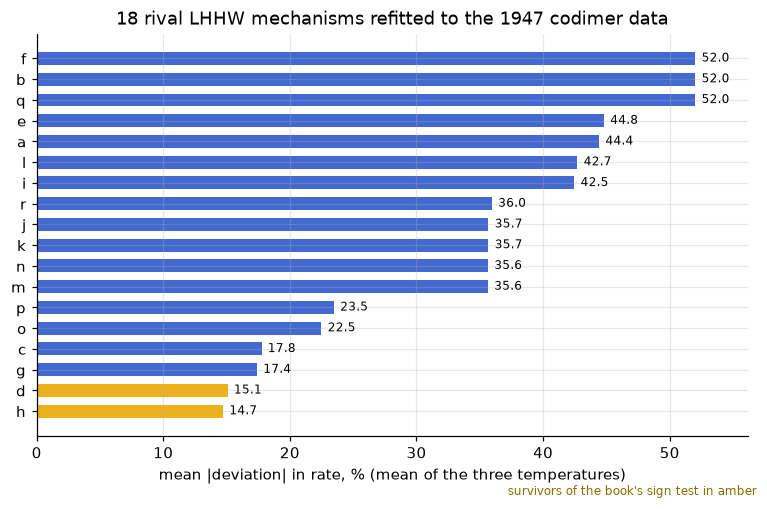

In [11]:
# Fit all 18 rate laws per temperature: positive parameters through a log
# reparameterisation, Levenberg-Marquardt from three fixed starts, each fit's
# status and gradient checked.
def paired(F, m1, m2, temps=TEMPS):
    """Mean over ``temps`` of the per-temperature mean paired difference of absolute
    percentage deviations (m1 minus m2), and its standard error."""
    diffs = [F[(m1, T)]["pct"] - F[(m2, T)]["pct"] for T in temps]
    gap = float(np.mean([d.mean() for d in diffs]))
    se = float(np.sqrt(sum(np.var(d, ddof=1) / d.size for d in diffs)) / len(diffs))
    return gap, se


def nested_f(full, reduced, df1):
    """Extra-sum-of-squares F test of a reduced rate law against the full one, both fitted
    by minimising the sum of squared relative residuals (the loss ``fit_rate`` minimises):
    ``df1`` parameters dropped. Returns the statistic and its p value."""
    ss_full, ss_red = np.sum((full["pct"] / 100) ** 2), np.sum((reduced["pct"] / 100) ** 2)
    df2 = full["dof"]
    stat = (ss_red - ss_full) / df1 / (ss_full / df2)
    return float(stat), float(stats.f.sf(stat, df1, df2))


def nls_study(data=None, max_nfev=40000, generator="h", reduced=RATE_D_NO_KS):
    """``data`` replaces Table A; ``generator`` is the mechanism whose fitted 200 C rates
    the power study refits with mechanism d; ``reduced`` is the law d is tested against
    after dropping K_S p_S (the nested F test at 200 C)."""
    AA = A if data is None else data
    F = {}
    for T in TEMPS:
        H, U, S, r = cols(AA[AA.temp_C == T])
        for m in MECH_RATE:
            F[(m, T)] = fit_rate(MECH_RATE[m], H, U, S, r, max_nfev=max_nfev)
    pool = {m: float(np.mean([F[(m, T)]["pct"].mean() for T in TEMPS])) for m in MECH_RATE}
    best = min(pool, key=pool.get)
    z = {m: paired(F, m, best)[0] / paired(F, m, best)[1] for m in MECH_RATE if m != best}
    dh_best = min("dh", key=pool.get)
    gap_dh, se_dh = paired(F, "d", "h")
    third = min((m for m in pool if m not in "dh"), key=pool.get)
    gap3, se3 = paired(F, third, dh_best)
    H, U, S, r = cols(AA[AA.temp_C == 200])
    noks = fit_rate(reduced, H, U, S, r, max_nfev=max_nfev)
    F[("d-noKS", 200)] = noks
    f_ks, p_ks = nested_f(F[("d", 200)], noks, df1=MECH_RATE["d"][0] - RATE_D_NO_KS[0])
    gap200, se200 = paired(F, "d", "h", temps=(200,))      # d minus h: positive when h fits better
    r_gen = MECH_RATE[generator][1](F[(generator, 200)]["p"], H, U, S)
    power = fit_rate(MECH_RATE["d"], H, U, S, r_gen, max_nfev=max_nfev)
    fits = [f for k, f in F.items()] + [power]
    resolved = [m for m in z if z[m] >= Z_RESOLVED]
    return {"F": F, "pool": pool, "best": best, "z": z, "third": third, "gap200": gap200, "se200": se200,
            "nls_d_mean_abs_pct_pooled": pool["d"], "nls_h_mean_abs_pct_pooled": pool["h"],
            "discrim_d_vs_h_gap_pct_points": abs(gap_dh), "discrim_d_vs_h_gap_se_pts": se_dh,
            "discrim_d_vs_h_gap_over_se": abs(gap_dh) / se_dh,
            "discrim_third_best_gap_pct_points": gap3, "discrim_third_best_gap_se_pts": se3,
            "discrim_third_best_gap_over_se": gap3 / se3,
            "nls_unresolved_from_best": int(sum(v < Z_RESOLVED for v in z.values())),
            "nls_resolved_ratio_min": min(pool[m] / pool["d"] for m in resolved),
            "nls_resolved_ratio_max": max(pool[m] / pool["d"] for m in resolved),
            "nls_d_noKS_200C_mean_abs_pct": float(noks["pct"].mean()),
            "nls_noKS_F_200C": f_ks, "nls_noKS_F_pvalue_200C": p_ks,
            "discrim_power_d_fits_exact_h_pct": float(power["pct"].mean()),
            "nls_fits_converged": int(sum(f["status"] > 0 for f in fits)),
            "nls_fit_max_gradient": max(f["grad"] for f in fits)}


NL = nls_study()
F, pool = NL["F"], NL["pool"]
for name in ("nls_d_mean_abs_pct_pooled", "nls_h_mean_abs_pct_pooled", "discrim_d_vs_h_gap_pct_points",
             "discrim_d_vs_h_gap_se_pts", "discrim_third_best_gap_pct_points", "discrim_third_best_gap_se_pts",
             "nls_resolved_ratio_min", "nls_resolved_ratio_max", "nls_d_noKS_200C_mean_abs_pct",
             "nls_noKS_F_200C", "discrim_power_d_fits_exact_h_pct"):
    claims.value(name, NL[name], rtol=0.05)
for name in ("discrim_d_vs_h_gap_over_se", "discrim_third_best_gap_over_se"):
    claims.bound(name, NL[name], max=Z_RESOLVED, basis="chosen",
                 note="the verdict 'not resolved': the paired gap is below Z_RESOLVED standard errors")
claims.bound("nls_noKS_F_pvalue_200C", NL["nls_noKS_F_pvalue_200C"], max=0.05, basis="chosen",
             note="the verdict 'resolved': the nested F test rejects the model without K_S p_S at the 5 % level")
claims.count("nls_unresolved_from_best", list(NL["z"].values()), Z_RESOLVED, above=False, min_margin=0.1,
             note="mechanisms whose paired gap to the best fit is below Z_RESOLVED standard errors")
claims.exact("nls_fits_converged", NL["nls_fits_converged"])
claims.bound("nls_fit_max_gradient", NL["nls_fit_max_gradient"], max=1e-4, basis="tolerance",
             note="infinity norm of the cost gradient in the log-parameters at every solution")

disc = pd.DataFrame([(m, *[F[(m, T)]["pct"].mean() for T in TEMPS], pool[m],
                      NL["z"].get(m, np.nan)) for m in MECH_RATE],
                    columns=["mech", "200C", "275C", "325C", "pooled", "gap to best / SE"]).sort_values("pooled")
show(disc.style.format({c: "{:.1f}" for c in disc.columns[1:]}).hide(axis="index"), "c1105")
se_tbl = pd.DataFrame([(m, T, F[(m, T)]["n"], F[(m, T)]["dof"], *F[(m, T)]["p"], *F[(m, T)]["se_log"])
                       for m in "dh" for T in TEMPS],
                      columns=["mech", "T_C", "n", "dof", "alpha K_H K_U", "K_H", "K_U", "K_S",
                               "SE ln(alpha K_H K_U)", "SE ln K_H", "SE ln K_U", "SE ln K_S"])
show(se_tbl.style.format({c: "{:.3g}" for c in se_tbl.columns[4:]}).hide(axis="index"), "c1109")
n_unres = claims["nls_unresolved_from_best"]
unres = sorted((m for m in NL["z"] if NL["z"][m] < Z_RESOLVED), key=pool.get)
display(Markdown(f"""
Every one of the {claims['nls_fits_converged']} fits stops on a converged status, with the cost
gradient at the solution at most 1e-4 (here {claims['nls_fit_max_gradient']:.0e}); the
standard errors above use $s^2 = \\Sigma\\,\\text{{res}}^2/(n - p)$ with the $n$ and degrees of
freedom listed (an infinite entry marks a parameter driven to zero, where $J^TJ$ is singular).

**The data cannot separate the two surviving mechanisms.** Pooled over the
three temperatures, mechanism d fits to **{claims['nls_d_mean_abs_pct_pooled']:.1f} %** mean absolute
deviation in rate and mechanism h to **{claims['nls_h_mean_abs_pct_pooled']:.1f} %**: a gap of
{claims['discrim_d_vs_h_gap_pct_points']:.2f} percentage points with a paired standard error of
{claims['discrim_d_vs_h_gap_se_pts']:.2f}, so {claims['discrim_d_vs_h_gap_over_se']:.1f} standard errors,
**not resolved** (the threshold is {Z_RESOLVED:g}). At 200 C alone h is ahead by
{NL['gap200']:.1f} points, {NL['gap200'] / NL['se200']:.1f} standard errors, not resolved either. The
book's stated ground that "the experimental fit is better with mechanism d" therefore does not
survive refitting in rate space: the choice of d rests, as the book's second argument already had
it, on chemistry (no dissociation needed), not statistics. The failure is structural, not a
noise problem: *noiseless* rates generated from the fitted h are captured by
mechanism d to {claims['discrim_power_d_fits_exact_h_pct']:.1f} % over the same
12 compositions of the 200 C block, against d's own {F[('d', 200)]['pct'].mean():.1f} % on the measured
rates there. Kiani & Wachs
(2024) make the same point about the pair-site content of these fits from the
surface-science side.

**What the fits do resolve.** {n_unres} mechanisms sit within {Z_RESOLVED:g} standard errors of the
best fit ({claims['nls_h_mean_abs_pct_pooled']:.1f} %, mechanism {NL['best']}): {", ".join(unres)}. The
best rejected mechanism ({NL['third']}, desorption control) is
{claims['discrim_third_best_gap_pct_points']:.1f} points behind with a standard error of
{claims['discrim_third_best_gap_se_pts']:.1f} ({claims['discrim_third_best_gap_over_se']:.1f} standard
errors), and dropping $K_Sp_S$ from d raises the 200 C deviation from
{F[('d', 200)]['pct'].mean():.1f} to {claims['nls_d_noKS_200C_mean_abs_pct']:.1f} %, which the nested
extra-sum-of-squares test ({MECH_RATE['d'][0]} against {RATE_D_NO_KS[0]} parameters, {F[('d', 200)]['n']} runs) resolves: F =
{claims['nls_noKS_F_200C']:.1f}, p = {claims['nls_noKS_F_pvalue_200C']:.2f}. Fit quality therefore
resolves the product term but not the control step: the desorption-controlled forms are not
resolved from the survivors. The remaining
{len(MECH_RATE) - 1 - n_unres} mechanisms are resolved: they fit
{claims['nls_resolved_ratio_min']:.1f} to {claims['nls_resolved_ratio_max']:.1f} times worse than d,
among them the forms missing $p_U$ or $p_H$ in the numerator and the uncatalysed $r = kp_Hp_U$. The
book's sign test, not the fit quality, is what separates {", ".join(sorted(set(unres) - {"d", "h"}))}
from d and h.
"""))

fig, ax = plt.subplots(figsize=(7.0, 4.6))
dd = disc.sort_values("pooled", ascending=True)
cols_bar = ["#efb118" if m in ("d", "h") else "#4269d0" for m in dd.mech]
ax.barh(np.arange(len(dd)), dd.pooled, color=cols_bar, height=0.62)
ax.set_yticks(np.arange(len(dd)), dd.mech)
ax.set_xlabel("mean |deviation| in rate, % (mean of the three temperatures)")
ax.set_title("18 rival LHHW mechanisms refitted to the 1947 codimer data")
for i, (m, v) in enumerate(zip(dd.mech, dd.pooled)):
    ax.text(v + 0.5, i, f"{v:.1f}", va="center", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
ax.margins(x=0.08)
fig.text(0.99, 0.01, "survivors of the book's sign test in amber", ha="right", fontsize=8, color="#8a6d00")
plt.tight_layout(); plt.show()

### 4. The temperature correlation, Table G, and the eq. (q) misprint

In [12]:
# Reproduce the book's two-step temperature treatment and adjudicate dS_S.
T3 = np.array([T_OF[t] for t in TEMPS])
GCOLS = ["val_200C", "val_275C", "val_325C"]


def tempcorr_study(abscissa="1/T", swap=False, dss_table=None, dss_eqq=None):
    """``abscissa`` of the straight lines, ``swap`` the K_U and K_H relations of eq. (n),
    ``dss_table`` and ``dss_eqq`` replace the two printed dS_S."""
    x = 1 / T3 if abscissa == "1/T" else T3
    row = lambda k: TG.loc[k, GCOLS].to_numpy(float)
    corr = {}
    for k in "abcf":
        slope, icept = np.polyfit(x, np.log(row(f"{k}_experimental")), 1)
        corr[k] = np.exp(icept + slope * x)
    ap, bp, cp, fp = (row(f"{k}_corrected") for k in "abcf")
    derived = {"K_U": (fp if swap else bp) / ap, "K_S": cp / ap, "K_H": (bp if swap else fp) / ap,
               "alpha_Ek": 1 / (ap**2 * (fp / ap) * (bp / ap))}
    vh = {}
    for key in ("K_U", "K_S", "K_H", "alpha_Ek"):
        slope, icept = np.polyfit(x, np.log(row(key)), 1)
        vh[key] = (-slope * RGAS, icept * RGAS)     # a T abscissa read as if it were 1/T
    dss_g = TH["dS_S"] if dss_table is None else dss_table
    dss_q = TH["dS_S_eqq"] if dss_eqq is None else dss_eqq
    KS_row = row("K_S")
    rms = lambda dss: float(np.sqrt(np.mean(((np.exp(-TH["dH_S"] / (RGAS * T3) + dss / RGAS) - KS_row)
                                              / KS_row) ** 2)))
    lo, hi = sorted((dss_g, dss_q))
    refit = vh["K_S"][1]
    return {"corr": corr, "vh": vh,
            "tableG_corrected_max_rel": float(max(np.max(np.abs(corr[k] - row(f"{k}_corrected"))
                                                         / row(f"{k}_corrected")) for k in "abcf")),
            "tableG_derived_K_max_rel": float(max(np.max(np.abs(v - row(k)) / row(k)) for k, v in derived.items())),
            "KS_row_rms_rel_tableG_dSS": rms(dss_g), "KS_row_rms_rel_eqq_dSS": rms(dss_q),
            "eqq_KS_low_pct": 100 * (1 - float(np.exp((dss_q - dss_g) / RGAS))),
            "KS_refit_dSS": refit,
            "KS_refit_between_printings": bool(lo < refit < hi),
            "between_margin": float(min(refit - lo, hi - refit) / (hi - lo)) if lo < refit < hi else 0.0}


TS = tempcorr_study()
corr_tbl = pd.DataFrame({f"{k} {lab}": arr for k in "abcf"
                         for lab, arr in (("(refit)", TS["corr"][k]),
                                          ("(printed)", TG.loc[f"{k}_corrected", GCOLS].to_numpy(float)))},
                        index=["200C", "275C", "325C"]).T
show(corr_tbl.style.format("{:.3f}"), "c1106")
vh_tbl = pd.DataFrame({
    "refit dH (or A)": {k: v[0] for k, v in TS["vh"].items()},
    "refit dS (or B)": {k: v[1] for k, v in TS["vh"].items()},
    "printed dH": {"K_U": TH["dH_U"], "K_S": TH["dH_S"], "K_H": TH["dH_H"], "alpha_Ek": -TH["A"]},
    "printed dS": {"K_U": TH["dS_U"], "K_S": TH["dS_S"], "K_H": TH["dS_H"], "alpha_Ek": TH["B"]}})
show(vh_tbl.style.format("{:.2f}"), "c1107")
for name in ("tableG_corrected_max_rel", "tableG_derived_K_max_rel", "KS_row_rms_rel_tableG_dSS",
             "KS_row_rms_rel_eqq_dSS", "eqq_KS_low_pct", "KS_refit_dSS"):
    claims.value(name, TS[name], rtol=0.05)
claims.exact("KS_refit_between_printings", TS["KS_refit_between_printings"], margin=TS["between_margin"],
             min_margin=0.05, note="margin: distance to the nearer printing over the gap between them")
display(Markdown(f"""
The corrected constants refit to within
**{claims['tableG_corrected_max_rel']:.1%}** of Table G (the book's hand-fitted lines), and the
derived $K$ rows close to **{claims['tableG_derived_K_max_rel']:.1%}**, confirming the printed
relations $K_U = b/a$, $K_S = c/a$, $K_H = f/a$, $\\alpha = 1/(a^2K_HK_U)$.

**The misprint, adjudicated.** With the printed $\\Delta H_S = {TH['dH_S']:g}$,
Table G's $\\Delta S_S = {TH['dS_S']:g}$ reproduces the printed $K_S$ row
({", ".join(f"{v:g}" for v in TG.loc['K_S', GCOLS])}) to **{claims['KS_row_rms_rel_tableG_dSS']:.1%}** rms;
eq. (q)'s ${TH['dS_S_eqq']:g}$ misses the same row by **{claims['KS_row_rms_rel_eqq_dSS']:.1%}**: the
final boxed equation carries the typo, the table is right. An implementation
typed from the (more convenient) eq. (q) box inherits a $K_S$
{claims['eqq_KS_low_pct']:.0f} % low. The free refit of the $K_S$ row lands at
$\\Delta S_S$ = {claims['KS_refit_dSS']:.2f}, numerically *between* the two printed values, so the
intercept alone adjudicates nothing; what settles it is the pair test above.
"""))

,200C,275C,325C
a (refit),2.659,3.176,3.488
a (printed),2.640,3.140,3.430
b (refit),1.531,1.584,1.613
b (printed),1.530,1.580,1.610
c (refit),1.383,0.199,0.071
c (printed),1.290,0.203,0.076
f (refit),1.084,0.772,0.646
f (printed),1.010,0.774,0.653


,refit dH (or A),refit dS (or B),printed dH,printed dS
K_U,-958.71,-3.11,-940.00,-3.08
K_S,-13911.63,-30.82,-13700.00,-30.46
K_H,-3139.20,-8.53,-3110.00,-8.49
alpha_Ek,1764.74,2.85,-1740.00,2.82



The corrected constants refit to within
**7.4%** of Table G (the book's hand-fitted lines), and the
derived $K$ rows close to **1.5%**, confirming the printed
relations $K_U = b/a$, $K_S = c/a$, $K_H = f/a$, $\alpha = 1/(a^2K_HK_U)$.

**The misprint, adjudicated.** With the printed $\Delta H_S = -13700$,
Table G's $\Delta S_S = -30.46$ reproduces the printed $K_S$ row
(0.489, 0.0646, 0.0222) to **2.5%** rms;
eq. (q)'s $-30.96$ misses the same row by **23.6%**: the
final boxed equation carries the typo, the table is right. An implementation
typed from the (more convenient) eq. (q) box inherits a $K_S$
22 % low. The free refit of the $K_S$ row lands at
$\Delta S_S$ = -30.82, numerically *between* the two printed values, so the
intercept alone adjudicates nothing; what settles it is the pair test above.



**The final correlation against the data it came from:** eq. (q) (with Table
G's $\Delta S_S$) reproduces the 40 measured rates to
**19.1 %** mean absolute deviation
(17.8 / 19.2 /
19.9 % at 200 / 275 / 325 C). That is *worse* than the book's famous
+-8.44 % for two reasons this page separates: the 8.44 is in the
transformed variable $R \propto 1/\sqrt{r}$, so it corresponds to about
**16.9 %** in the rate itself (at 200 C with the book's own
constants); the ratio of rate-space to transform-space deviation of the same linear fit is
2.00, the delta-method factor $1/\text{power} = 2$ for a
square root, measured (and 0.96 for the
untransformed $p_Hp_U/r$); and eq. (q) smooths the three per-temperature fits through the van 't Hoff
lines, paying a further few points for consistency in $T$. Both numbers are *fit quality on fitting
data*, not validation: the source contains no held-out measurement.

**The retardation the book makes so much of is real in its own constants:** at run 3c's
composition, eq. (q)'s rate peaks at **579 K (306 C)**, the root of
$\mathrm{d}\ln r/\mathrm{d}T$ (`find_roots` on 380 to 750 K, exactly one root). That is
inside the experimental window of
473.16 to 598.16 K (margin 15% of its width) and below the
~650 K reversibility threshold: the adsorption-starvation maximum Fig. 189 draws (computed here from
printed constants; the figure itself was never digitised). With the adsorption group deleted, the
derivative is the constant $A + \Delta H_H + \Delta H_U = -2310$ cal/mol,
so the rate falls monotonically and has no maximum at all.


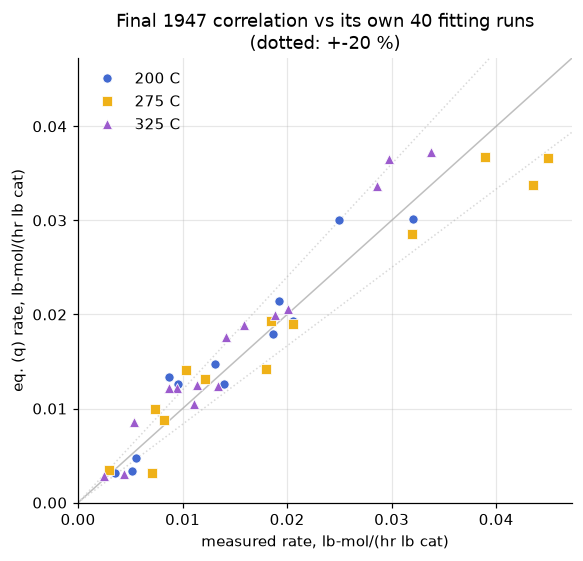

In [13]:
# Eq. (q) against all 40 measured rates, the rate-space size of the book's +-8.44 %,
# and the rate maximum eq. (q) implies.
RUN3C = A.set_index("run").loc["3c"]


def eqq_study(data=None, expo=2, dS_S=None):
    """``data`` replaces Table A, ``expo`` the adsorption-group exponent, ``dS_S`` Table G's dS_S."""
    AA = A if data is None else data
    TT = AA.temp_C.map(T_OF).to_numpy()
    H, U, S, r = cols(AA)
    r_pred = rate_eqq(TT, H, U, S, TH, dS_S=dS_S, expo=expo)
    pct = 100 * np.abs(r_pred - r) / r
    a2, b2, c2, f2 = (TG.loc[f"{k}_experimental", "val_200C"] for k in "abcf")
    H0, U0, S0, r0 = cols(AA[AA.temp_C == 200])
    r_lin = H0 * U0 / (a2 + f2 * H0 + b2 * U0 + c2 * S0) ** 2
    out = {"r_pred": r_pred, "r": r, "eqq_all40_mean_abs_pct": float(pct.mean()),
           "rate_space_scatter_pct_200C": float(np.mean(100 * np.abs(r_lin - r0) / r0))}
    out.update({f"eqq_mean_abs_pct_{t}C": float(pct[(AA.temp_C == t).to_numpy()].mean()) for t in TEMPS})
    return out


def ratio_study(power=0.5, data=None):
    """Rate-space over transform-space mean |deviation| of the linear fit of
    (pH pU / r)^power on the 200 C block: about 1/power for small errors."""
    AA = A if data is None else data
    H, U, S, r = cols(AA[AA.temp_C == 200])
    R = (H * U / r) ** power
    X = np.column_stack([np.ones_like(H), U, S, H])
    Rf = X @ np.linalg.lstsq(X, R, rcond=None)[0]
    rf = H * U / Rf ** (1 / power)
    return {"rate_space_over_R_space_ratio": float(np.mean(np.abs(rf - r) / r) / np.mean(np.abs(Rf - R) / R))}


def ratemax_study(thermo=None, expo=2):
    """Rate maximum in T at run 3c's composition; ``thermo`` replaces the printed constants."""
    th = TH if thermo is None else thermo
    T = rate_max_temperature(th, RUN3C.pH_atm, RUN3C.pU_atm, RUN3C.pS_atm, 380.0, 750.0, expo=expo)
    lo, hi = T_OF[200], T_OF[325]
    return {"rate_max_T_K_run3c_composition": T, "rate_max_inside_data_window": bool(lo < T < hi),
            "window_margin": float(min(T - lo, hi - T) / (hi - lo))}


EQ = eqq_study()
RA = ratio_study()
RM = ratemax_study()
for name in ("eqq_all40_mean_abs_pct", "eqq_mean_abs_pct_200C", "eqq_mean_abs_pct_275C", "eqq_mean_abs_pct_325C",
             "rate_space_scatter_pct_200C"):
    claims.value(name, EQ[name], rtol=0.05)
claims.value("rate_space_over_R_space_ratio", RA["rate_space_over_R_space_ratio"], rtol=0.05)
claims.value("rate_max_T_K_run3c_composition", RM["rate_max_T_K_run3c_composition"], rtol=1e-3, unit="K")
claims.exact("rate_max_inside_data_window", RM["rate_max_inside_data_window"], margin=RM["window_margin"],
             min_margin=0.05, note="margin: distance to the nearer end of 473.16 to 598.16 K over its width")
Tm = claims["rate_max_T_K_run3c_composition"]
display(Markdown(f"""
**The final correlation against the data it came from:** eq. (q) (with Table
G's $\\Delta S_S$) reproduces the 40 measured rates to
**{claims['eqq_all40_mean_abs_pct']:.1f} %** mean absolute deviation
({claims['eqq_mean_abs_pct_200C']:.1f} / {claims['eqq_mean_abs_pct_275C']:.1f} /
{claims['eqq_mean_abs_pct_325C']:.1f} % at 200 / 275 / 325 C). That is *worse* than the book's famous
+-{PRINTED['avg abs pct']} % for two reasons this page separates: the {PRINTED['avg abs pct']} is in the
transformed variable $R \\propto 1/\\sqrt{{r}}$, so it corresponds to about
**{claims['rate_space_scatter_pct_200C']:.1f} %** in the rate itself (at 200 C with the book's own
constants); the ratio of rate-space to transform-space deviation of the same linear fit is
{claims['rate_space_over_R_space_ratio']:.2f}, the delta-method factor $1/\\text{{power}} = 2$ for a
square root, measured (and {ratio_study(1.0)['rate_space_over_R_space_ratio']:.2f} for the
untransformed $p_Hp_U/r$); and eq. (q) smooths the three per-temperature fits through the van 't Hoff
lines, paying a further few points for consistency in $T$. Both numbers are *fit quality on fitting
data*, not validation: the source contains no held-out measurement.

**The retardation the book makes so much of is real in its own constants:** at run 3c's
composition, eq. (q)'s rate peaks at **{Tm:.0f} K ({Tm - 273.16:.0f} C)**, the root of
$\\mathrm{{d}}\\ln r/\\mathrm{{d}}T$ (`find_roots` on 380 to 750 K, exactly one root). That is
{"inside" if claims['rate_max_inside_data_window'] else "outside"} the experimental window of
{T_OF[200]:g} to {T_OF[325]:g} K (margin {RM['window_margin']:.0%} of its width) and below the
~650 K reversibility threshold: the adsorption-starvation maximum Fig. 189 draws (computed here from
printed constants; the figure itself was never digitised). With the adsorption group deleted, the
derivative is the constant $A + \\Delta H_H + \\Delta H_U = {TH['A'] + TH['dH_H'] + TH['dH_U']:g}$ cal/mol,
so the rate falls monotonically and has no maximum at all.
"""))

fig, ax = plt.subplots(figsize=(5.4, 5.2))
style = {200: ("#4269d0", "o"), 275: ("#efb118", "s"), 325: ("#9c5bcd", "^")}
for t, (col, mk) in style.items():
    m = (A.temp_C == t).to_numpy()
    ax.plot(EQ["r"][m], EQ["r_pred"][m], mk, color=col, ms=6, mec="white", mew=0.5, label=f"{t} C")
lim = [0, 1.05 * max(EQ["r"].max(), EQ["r_pred"].max())]
ax.plot(lim, lim, "-", color="0.75", lw=1, zorder=0)
ax.plot(lim, [1.2 * x for x in lim], ":", color="0.85", lw=1, zorder=0)
ax.plot(lim, [x / 1.2 for x in lim], ":", color="0.85", lw=1, zorder=0)
ax.set_xlabel("measured rate, lb-mol/(hr lb cat)")
ax.set_ylabel("eq. (q) rate, lb-mol/(hr lb cat)")
ax.set_title("Final 1947 correlation vs its own 40 fitting runs\n(dotted: +-20 %)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(lim); ax.set_ylim(lim)
plt.tight_layout(); plt.show()

### 5. The fitted law in a bed: a pymrm plug-flow demonstration

Chapter XXI poses exactly this problem (its Problem 1: isothermal bed, pure
codimer feed, hydrogen 40 per cent over stoichiometric, 99.8 per cent
hydrogenation, using "the nickel catalyst of Illustration 2") but at 250 to 350 F,
*below* the temperature range of the constants, and prints no answer. The
demonstration therefore runs at 200 C and 3.5 atm, inside the fitted range.
It is labelled a demonstration: no printed target exists.

Two independent routes: the pymrm finite-volume bed (upwind convection of the
three molar flows in catalyst-mass coordinate, Newton with a `NumJac((n, 3))`
pointwise-coupled stencil, the bed length a root of the outlet conversion), and
adaptive quadrature of the design equation $W/F_{U0} = \int_0^{X} \mathrm{d}X / r(X)$.
They share the rate function, so their agreement tests the transport
discretisation and nothing about the rate law, and they share nothing else.


**W/F for 99.8 % hydrogenation at 200 C, 3.5 atm:
106.62 lb cat (lb-mol U/hr)$^{-1}$** from the pymrm bed, extrapolated
from the grid ladder 100, 200, 400, 800, 1600 cells (the finest grid is
2.0e-03 from it, relative). Observed orders from successive
differences, 1.023, 1.011, 1.006, are the first order of upwind convection
(theory range 0.9 to 1.1); the finest difference is at least 1e3 times the root and Newton tolerances
(here 9e+07). The quadrature gives
106.6227, with an error of at most 1e-9 relative (here
2e-14); the extrapolated bed agrees with it to at most 1e-4
(here 1.0e-05), and the 800-cell bed sits
4.0e-03 above it, its first-order discretisation error.

**The contraction is not a refinement.** Total molar flow falls
41.6% across the bed (the outlet face of the finest bed,
`compute_boundary_values`); holding the total at its inlet value, a one-line slip that produces a
perfectly smooth, plausible profile, lengthens the required bed by
**51%** (two quadratures that differ only in the
total). The book's own Chapter XXI material balance (Table LXI) is precisely this bookkeeping, done
by hand.


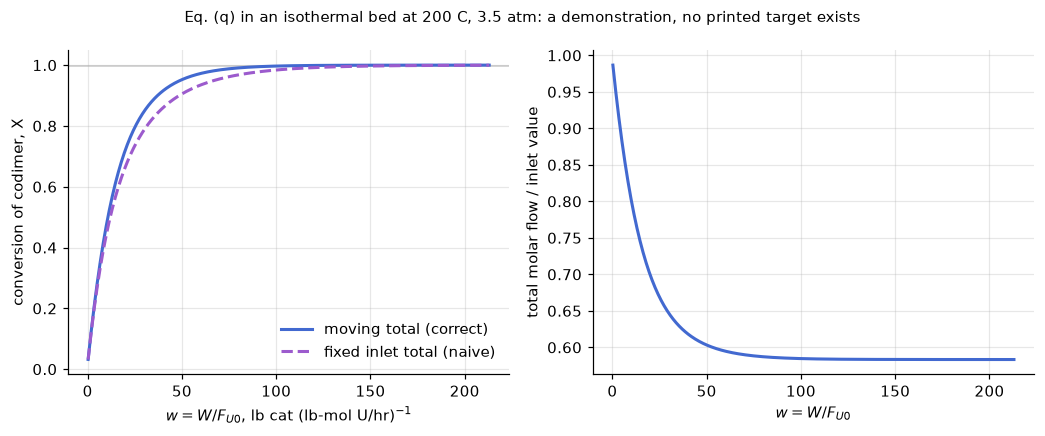

In [14]:
# Plug-flow bed at 200 C, 3.5 atm: W/F for 99.8 % hydrogenation. U + H2 -> S removes
# one mole per mole converted, so the partial pressures follow the LOCAL total flow.
T_BED = T_OF[200]


def bed_rate(dS_S=None):
    """Eq. (q) at the bed temperature as rate(pH, pU, pS)."""
    return lambda pH, pU, pS: rate_eqq(T_BED, pH, pU, pS, TH, dS_S=dS_S)


def quad_study(P=P_BED, nu=NU, x_target=X_TARGET, epsrel=1e-12):
    """W/F by quadrature (relative tolerance ``epsrel``), with its tolerance check and the
    fixed-total bias."""
    rate = bed_rate()
    W, err = wf_quadrature(rate, x_target, FEED, nu, P, epsrel=epsrel)
    W9, _ = wf_quadrature(rate, x_target, FEED, nu, P, epsrel=1e-9)
    Wn, _ = wf_quadrature(rate, x_target, FEED, nu, P, moving_total=False)
    return {"reactor_WF_998_quadrature": W, "reactor_WF_quad_tolerance_rel": max(err, abs(W9 - W)) / W,
            "reactor_naive_fixed_total_bias_rel": (Wn - W) / W}


def column_study(P=P_BED, nu=NU, moving_total=True, outlet_bc=None, xtol=1e-9, ns=NS_BED, cells=None):
    """The pymrm bed on the grid ladder ``ns``: the root W/F per grid, observed orders,
    the extrapolated value, and the outlet state of the finest bed. ``cells`` maps a rung
    of the ladder to the cell count actually solved (a typed ladder entry)."""
    cells = cells or {}
    rate = bed_rate()
    Wq = wf_quadrature(rate, X_TARGET, FEED, nu, P)[0]
    kw = dict(feed=FEED, nu=nu, P=P, moving_total=moving_total, outlet_bc=outlet_bc)
    st = observed_orders(lambda n: bed_wf(rate, cells.get(n, n), X_TARGET, 0.6 * Wq, 2.5 * Wq, xtol=xtol, **kw),
                         ns)
    W = dict(zip(ns, st["values"]))
    bed = IsothermalBed(rate, ns[-1], W[ns[-1]], **kw).solve()
    newton_tol = 1e-11 * max(FEED)          # the bed's Newton step tolerance, in flows of order one
    return {"W": W, "st": st, "bed": bed,
            "reactor_WF_extrapolated": st["extrapolated"],
            "reactor_WF_extrap_error_rel": st["error_estimate"] / st["extrapolated"],
            "reactor_WF_two_routes_rel_n800": abs(W[800] - Wq) / Wq,
            "reactor_WF_richardson_vs_quad_rel": abs(st["extrapolated"] - Wq) / Wq,
            "reactor_observed_order_min": float(np.min(st["orders"])),
            "reactor_observed_order_max": float(np.max(st["orders"])),
            "reactor_order_roundoff_margin": abs(W[ns[-1]] - W[ns[-2]]) / (xtol + newton_tol * Wq),
            "reactor_total_flow_contraction": 1 - bed.outlet().sum() / sum(FEED)}


QS = quad_study()
CS = column_study()
claims.value("reactor_WF_998_quadrature", QS["reactor_WF_998_quadrature"], rtol=1e-3)
claims.bound("reactor_WF_quad_tolerance_rel", QS["reactor_WF_quad_tolerance_rel"], max=1e-9, basis="tolerance",
             note="quad's own error estimate and the gap to a second tolerance, relative")
claims.value("reactor_naive_fixed_total_bias_rel", QS["reactor_naive_fixed_total_bias_rel"], rtol=0.05)
claims.value("reactor_WF_extrapolated", CS["reactor_WF_extrapolated"], rtol=1e-3)
claims.value("reactor_WF_extrap_error_rel", CS["reactor_WF_extrap_error_rel"], rtol=0.05)
claims.value("reactor_WF_two_routes_rel_n800", CS["reactor_WF_two_routes_rel_n800"], rtol=0.05)
claims.bound("reactor_WF_richardson_vs_quad_rel", CS["reactor_WF_richardson_vs_quad_rel"], max=1e-4,
             basis="chosen", note="the second-order remainder of a first-order extrapolation on this ladder")
claims.bound("reactor_observed_order_min", CS["reactor_observed_order_min"], min=0.9, max=1.1, basis="theory")
claims.bound("reactor_observed_order_max", CS["reactor_observed_order_max"], min=0.9, max=1.1, basis="theory")
claims.bound("reactor_order_roundoff_margin", CS["reactor_order_roundoff_margin"], min=1e3, basis="theory",
             note="finest successive difference over the root and Newton tolerances")
claims.value("reactor_total_flow_contraction", CS["reactor_total_flow_contraction"], rtol=0.05)

st = CS["st"]
display(Markdown(f"""
**W/F for 99.8 % hydrogenation at 200 C, 3.5 atm:
{claims['reactor_WF_extrapolated']:.2f} lb cat (lb-mol U/hr)$^{{-1}}$** from the pymrm bed, extrapolated
from the grid ladder {", ".join(str(n) for n in NS_BED)} cells (the finest grid is
{claims['reactor_WF_extrap_error_rel']:.1e} from it, relative). Observed orders from successive
differences, {", ".join(f"{p:.3f}" for p in st["orders"])}, are the first order of upwind convection
(theory range 0.9 to 1.1); the finest difference is at least 1e3 times the root and Newton tolerances
(here {claims['reactor_order_roundoff_margin']:.0e}). The quadrature gives
{claims['reactor_WF_998_quadrature']:.4f}, with an error of at most 1e-9 relative (here
{claims['reactor_WF_quad_tolerance_rel']:.0e}); the extrapolated bed agrees with it to at most 1e-4
(here {claims['reactor_WF_richardson_vs_quad_rel']:.1e}), and the 800-cell bed sits
{claims['reactor_WF_two_routes_rel_n800']:.1e} above it, its first-order discretisation error.

**The contraction is not a refinement.** Total molar flow falls
{claims['reactor_total_flow_contraction']:.1%} across the bed (the outlet face of the finest bed,
`compute_boundary_values`); holding the total at its inlet value, a one-line slip that produces a
perfectly smooth, plausible profile, lengthens the required bed by
**{claims['reactor_naive_fixed_total_bias_rel']:.0%}** (two quadratures that differ only in the
total). The book's own Chapter XXI material balance (Table LXI) is precisely this bookkeeping, done
by hand.
"""))

bed = IsothermalBed(bed_rate(), 400, 2.0 * claims["reactor_WF_998_quadrature"], feed=FEED, nu=NU, P=P_BED).solve()
naive = IsothermalBed(bed_rate(), 400, 2.0 * claims["reactor_WF_998_quadrature"], feed=FEED, nu=NU, P=P_BED,
                      moving_total=False).solve()
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.0))
ax = axes[0]
ax.plot(bed.w_c, 1 - bed.N[:, 0], color="#4269d0", lw=2, label="moving total (correct)")
ax.plot(naive.w_c, 1 - naive.N[:, 0], color="#9c5bcd", lw=2, ls="--", label="fixed inlet total (naive)")
ax.axhline(X_TARGET, color="0.8", lw=1, zorder=0)
ax.set_xlabel(r"$w = W/F_{U0}$, lb cat (lb-mol U/hr)$^{-1}$")
ax.set_ylabel("conversion of codimer, X")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
ax = axes[1]
ax.plot(bed.w_c, bed.N.sum(axis=1) / sum(FEED), color="#4269d0", lw=2)
ax.set_xlabel(r"$w = W/F_{U0}$")
ax.set_ylabel("total molar flow / inlet value")
ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Eq. (q) in an isothermal bed at 200 C, 3.5 atm: a demonstration, no printed target exists",
             fontsize=10)
plt.tight_layout(); plt.show()

## Validation

Everything numbered on this page is checked by one of four kinds of evidence,
and every reported number has a break row, a deliberate defect entered through
a call argument or a physical parameter that makes its own check fail:

1. **printed checksums**: the book's own sums prove the 200 C transcription;
2. **printed intermediates**: normal equations, eliminated system, solution,
   $\Sigma\delta^2$, the +-8.44, Tables C to G;
3. **two-route computations**: constants from transcribed data vs from the
   book's printed sums; W/F from a pymrm grid vs adaptive quadrature; the
   corrupted-worksheet value from two independent printed rows;
4. **the adjudications**: each printed inconsistency (25a, the $\Delta S_S$
   misprint, the duplicate-row disagreements) is decided by the book's own
   adjacent numbers, never by preference.

**What the break table cannot see, stated plainly:** the two reactor routes
share the rate function, so their agreement can never catch an error in
eq. (q) itself (the eq. (q)-vs-data comparison and the K-row reproductions
carry that load); the 275/325 transcriptions have no printed checksum, so a
transcription slip there is only caught if it disturbs the Table E/F
reproduction beyond the book's own rounding; and no perturbation can detect
that *all* comparisons stand on the same 40 runs: there is no independent
measurement anywhere in this source, which is why every agreement above is
labelled reproduction, not validation.

In [15]:
# The break table: each row injects one defect through a study's arguments and
# re-runs the study; brk_moved records every claim the defect moves.
import warnings


def slipped(data, run, column, value=None, factor=None):
    """A copy of a table with one cell mistyped."""
    out = data.copy()
    i = out.index[out.run == run][0]
    out.loc[i, column] = value if factor is None else out.loc[i, column] * factor
    return out


def noiseless(mech):
    """Table A with every rate replaced by mechanism ``mech``'s fitted rate at its run."""
    out = A.copy()
    for T in TEMPS:
        m = (out.temp_C == T).to_numpy()
        H, U, S, _ = cols(out[m])
        out.loc[m, "r_lbmol_per_lb_hr"] = MECH_RATE[mech][1](F[(mech, T)]["p"], H, U, S)
    return out


SLIP_10A = slipped(A, "10a", "pS_atm", 2.583)          # 2.538 typed as 2.583
first = {T: A[A.temp_C == T].run.iloc[0] for T in TEMPS}
RATE_SLIP = {T: slipped(A, first[T], "r_lbmol_per_lb_hr", factor=10.0) for T in TEMPS}
TC_25A = slipped(TC, "25a", "R_calc_printed", MD["consistent25"])
TC_DSQ = slipped(TC, "10a", "delta_sq_printed", factor=10.0)
TC_REXP = slipped(TC, "10a", "R_exp_printed", factor=1.1)
DEF_DUP = DEF.copy()
DEF_DUP.loc[(DEF_DUP.mechanism == "r") & (DEF_DUP.temp_C == 275), "c"] = 4.45
DEF_F275 = DEF.copy()
DEF_F275.loc[(DEF_F275.mechanism == "f") & (DEF_F275.temp_C == 275), "b"] *= 10.0
DEF_GM275 = DEF.copy()
DEF_GM275.loc[DEF_GM275.mechanism.isin(["g", "m"]) & (DEF_GM275.temp_C == 275), "a"] /= 10.0
TH_A = TH.copy()
TH_A["A"] = -TH["A"]
BAD_BOOK = BOOK_D200.copy()
BAD_BOOK[0] = 2.746                                    # 2.764 typed as 2.746
COLUMN = ["reactor_WF_extrapolated", "reactor_WF_extrap_error_rel", "reactor_WF_two_routes_rel_n800",
          "reactor_WF_richardson_vs_quad_rel", "reactor_observed_order_min", "reactor_observed_order_max",
          "reactor_order_roundoff_margin", "reactor_total_flow_contraction"]
SWEEP_EXT = 0.5
NEWLY_PASS = sorted(set(verdict_study(swept=THR_SWEEP + (SWEEP_EXT,))["sweep"][SWEEP_EXT][1])
                    - set(VS["sweep"][THR_SIGN][1]))
ROWS = [
    ("specimen per cent per unit index 5510 for 5150", lambda: specimen(factor=5510.0), None),
    ("Table A run 10a pS typed 2.583 for 2.538", lambda: {**checksums(SLIP_10A[SLIP_10A.temp_C == 200]),
                                                          **mechd_study(SLIP_10A[SLIP_10A.temp_C == 200]),
                                                          **def_study(SLIP_10A)}, None),
    ("Table C run 10a R_exp read 10 % high", lambda: {**checksums(tc=TC_REXP)}, None),
    ("Table C run 25a R_calc read as its row-consistent value", lambda: mechd_study(tc=TC_25A), None),
    ("Table C run 10a delta^2 read with a decimal slip", lambda: mechd_study(tc=TC_DSQ), None),
    ("printed solution a typed 2.746 for 2.764", lambda: mechd_study(book=BAD_BOOK), None),
    *[(f"rate of run {first[T]} ({T} C) with a decimal slip (x10)",
       (lambda T=T: {**def_study(RATE_SLIP[T]), **verdict_study(def_study(RATE_SLIP[T])["diag"]),
                     **nls_study(RATE_SLIP[T]), **eqq_study(RATE_SLIP[T]), **ratio_study(data=RATE_SLIP[T]),
                     **(mechd_study(RATE_SLIP[T][RATE_SLIP[T].temp_C == 200]) if T == 200 else {})}), None)
      for T in TEMPS],
    ("mechanism h regressed on pH instead of sqrt(pH)",
     lambda: {**def_study(h_basis="pH"), **verdict_study(def_study(h_basis="pH")["diag"])}, None),
    ("200 C anomaly attributed to Sum R pU instead of Sum R pS", lambda: def_study(element=1), None),
    ("r's c at 275 C typed as its siblings' 4.45", lambda: def_study(table=DEF_DUP), None),
    ("f's b at 275 C typed with a decimal slip (x10)", lambda: def_study(table=DEF_F275), None),
    ("g/m's a at 275 C typed -31.1 for -311", lambda: def_study(table=DEF_GM275), None),
    ("sign-test threshold 1 % instead of 5 %", lambda: verdict_study(thr=0.01), None),
    (f"sensitivity: sign-test sweep extended to {SWEEP_EXT:.0%} ({', '.join(NEWLY_PASS)} then pass)",
     lambda: verdict_study(swept=THR_SWEEP + (SWEEP_EXT,)), None),
    ("rates replaced by noiseless mechanism-(h) rates", lambda: nls_study(noiseless("h")), None),
    ("rate-space fits capped at 5 evaluations", lambda: nls_study(max_nfev=5), None),
    ("copies' printing unit ten times coarser (half a unit of the constant moves the sums ten times more)",
     lambda: def_study(unit_factor=10.0), None),
    ("K_S p_S test against the full mechanism d (nothing dropped, F = 0)",
     lambda: nls_study(reduced=MECH_RATE["d"]), None),
    ("power study generated from mechanism d (exact for d by construction)",
     lambda: nls_study(generator="d"), None),
    ("van 't Hoff lines fitted against T instead of 1/T", lambda: tempcorr_study(abscissa="T"), None),
    ("K_U and K_H relations of eq. (n) swapped", lambda: tempcorr_study(swap=True), None),
    ("Table G's dS_S replaced by eq. (q)'s", lambda: {**tempcorr_study(dss_table=TH["dS_S_eqq"]),
                                                     **eqq_study(dS_S=TH["dS_S_eqq"])}, None),
    ("eq. (q)'s dS_S read as Table G's", lambda: tempcorr_study(dss_eqq=TH["dS_S"]), None),
    ("adsorption-group exponent 1 instead of 2", lambda: {**eqq_study(expo=1), **ratemax_study(expo=1)}, None),
    ("transform pHpU/r instead of its square root", lambda: ratio_study(power=1.0), None),
    ("A of eq. (q) with its sign flipped", lambda: ratemax_study(thermo=TH_A), None),
    ("adsorption group deleted (exponent 0: d ln r/dT is the constant -2310 cal/mol, no maximum)",
     lambda: ratemax_study(expo=0), ["rate_max_T_K_run3c_composition", "rate_max_inside_data_window"]),
    ("bed at 1 atm instead of 3.5", lambda: {**quad_study(P=1.0), **column_study(P=1.0)}, None),
    ("saturate coefficient 2 (no mole change: the fixed total is exact)",
     lambda: {**quad_study(nu=(-1.0, -1.0, 2.0)), **column_study(nu=(-1.0, -1.0, 2.0))}, None),
    ("bed partial pressures from the fixed inlet total", lambda: column_study(moving_total=False), None),
    ("outlet a Dirichlet zero (S has no inflow, a positive source and no outflow: no steady state)",
     lambda: column_study(outlet_bc={"a": 0.0, "b": 1.0, "d": 0.0}), COLUMN),
    ("bed-length root tolerance 0.1 instead of 1e-9", lambda: column_study(xtol=0.1), None),
    ("conversion target 1 (the integral of 1/r diverges as p_U -> 0)", lambda: quad_study(x_target=1.0), None),
    ("quadrature relative tolerance 1e-4 instead of 1e-12", lambda: quad_study(epsrel=1e-4), None),
    ("bed ladder's 200-cell rung solved on 300 cells", lambda: column_study(cells={200: 300}), None),
]
# Two rows leave no solution at all, so their nan is the detection; each is shown by a
# route that needs no solver.
# (i) Dirichlet zero outlet: the upwind fluxes telescope, so summed over the bed the steady
# balance of species i reads N_i,in - N_i,out = -nu_i * int r dw at ANY state. With the
# outlet flows forced to zero, U, H2 and S then need int r dw = 1, 1.4 and 0 at once.
_dbed = IsothermalBed(bed_rate(), 40, 100.0, feed=FEED, nu=NU, P=P_BED,
                      outlet_bc={"a": 0.0, "b": 1.0, "d": 0.0})
_states = (_dbed.N.ravel(), np.random.default_rng(0).random(_dbed.N.size))
NEED_INT_R = [(np.diff(_dbed.w_f)[:, None] * (_dbed.L @ x + _dbed.b.ravel()).reshape(_dbed.N.shape)).sum(axis=0)
              / np.asarray(NU) for x in _states]
# (ii) conversion target 1: p_U is proportional to 1 - X, so (1 - X)/r tends to a positive
# constant and the integrand of W/F behaves as C/(1 - X), whose integral diverges.
_eps = np.array([1e-4, 1e-6, 1e-8])
_N1 = np.asarray(FEED)[None, :] + np.asarray(NU)[None, :] * (1 - _eps)[:, None]
_p1 = P_BED * _N1 / _N1.sum(axis=1, keepdims=True)
TAIL_C = _eps / bed_rate()(_p1[:, 1], _p1[:, 0], _p1[:, 2])
print("Dirichlet outlet: int r dw needed by the U, H2, S balances, two states: "
      + "; ".join(", ".join(f"{v:.3g}" for v in np.round(need, 12) + 0.0) for need in NEED_INT_R))
print("conversion target 1: (1 - X)/r at 1 - X = " + ", ".join(f"{e:.0e}" for e in _eps)
      + ": " + ", ".join(f"{c:.4f}" for c in TAIL_C) + " (a positive limit: log divergence)")
BY_FAILURE = {ROWS[i][0] for i in range(len(ROWS))
              if ROWS[i][0].startswith(("outlet a Dirichlet zero", "conversion target 1 "))}
assert len(BY_FAILURE) == 2
assert all(np.allclose(need, -np.asarray(FEED) / np.asarray(NU), atol=1e-12) for need in NEED_INT_R)
assert np.all(TAIL_C > 0) and np.ptp(TAIL_C) < 1e-3 * TAIL_C[-1]

claims.define_rows([label for label, _, _ in ROWS])
for label, study, names in ROWS:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        if names is None:
            brk_moved(label, study(), by_failure=label in BY_FAILURE)
        else:
            brk_study(label, study, names, by_failure=label in BY_FAILURE)

bt = pd.DataFrame(BREAK, columns=["injected defect", "claim", "clean", "with defect", "caught"])
show(bt.style.hide(axis="index").format({"clean": lambda v: f"{v:.4g}" if isinstance(v, float) else str(v),
                                         "with defect": lambda v: f"{v:.4g}" if isinstance(v, float) else str(v)}),
     "c1108")
uncaught = bt[~bt.caught]
print(f"{len(ROWS)} rows, {len(bt)} recorded entries, {len(uncaught)} that move a claim within its tolerance")

injected defect,claim,clean,with defect,caught
specimen per cent per unit index 5510 for 5150,run3c_specimen_rate_vs_tableA_rel,0.006714,0.06272,True
Table A run 10a pS typed 2.583 for 2.538,tableA_linear_psum_max_abs,1.776e-15,0.045,True
Table A run 10a pS typed 2.583 for 2.538,tableA_product_psum_max_rel,8.526e-05,0.02528,True
Table A run 10a pS typed 2.583 for 2.538,tableA_product_psum_max_half_units,0.928,461.4,True
Table A run 10a pS typed 2.583 for 2.538,tableA_Rsum_check_max_rel,3.897e-05,0.006533,True
Table A run 10a pS typed 2.583 for 2.538,mechd_200C_vs_printed_max_rel,0.005764,0.01564,True
Table A run 10a pS typed 2.583 for 2.538,mechd_200C_two_routes_max_rel,0.006297,0.01511,True
Table A run 10a pS typed 2.583 for 2.538,tableC_sum_delta_sq_rel_dev,0.001376,0.004825,True
Table A run 10a pS typed 2.583 for 2.538,tableC_avg_abs_pct,8.424,8.449,False
Table A run 10a pS typed 2.583 for 2.538,tableC_other_Rcalc_worst_abs,0.0259,0.02617,False


35 rows, 185 recorded entries, 38 that move a claim within its tolerance


## What pymrm adds

**The rate algebra needs no solver**, and Sections 1 to 3 use no pymrm: that
work is transcription, linear algebra and `scipy.optimize`, and its value is
archival and statistical, not numerical. What the page adds over the book there
is (i) proof of which printed numbers are right, (ii) the forensic
identification of a single 1947 worksheet slip behind eight rows of Table D plus
the misprint adjudication in eq. (q), and (iii) the discrimination question with
standard errors: the founding dataset cannot resolve molecular vs atomic
hydrogen, nor the best rejected forms from the survivors, on fit quality.

pymrm contributes two things. `pymrm.checks.find_roots` locates the rate
maximum of eq. (q) as the single root of the analytic temperature derivative of
$\ln r$ on its window, and the bed length of Section 5 as the root of the outlet
conversion. And Section 5's bed is the `S2` pattern downstream LHHW pages reuse:
species on the last axis of a `(n, 3)` field, `NumJac((n, 3))` for a
pointwise-coupled source, upwind convection assembled once with the
outward-normal boundary convention and a `{"outflow": True}` outlet read by
`compute_boundary_values`, `newton` with its success checked, and
`pymrm.checks.observed_orders` for the grid ladder. The mole-contraction
bookkeeping it carries is the one the naive implementation silently drops at a
measured cost of half the bed.

## Reuse

- **Take the rate law from Table G's foot, not from eq. (q).** The boxed final
  equation misprints $\Delta S_S$ ($-30.96$ for $-30.46$), which this page
  adjudicates from the book's own $K_S$ row; typing the box costs the $K_S$
  fraction printed in Section 4. The `eqq-thermo` dataset carries both
  printings, labelled.
- **Do not quote Tables D/E/F's constants for the rejected mechanisms** without
  this page's forensics (Section 2): at 200 C the c and g/m families descend
  from one corrupted $\Sigma R\,p_S$; duplicate rows disagree with their printed
  siblings; the 275 C g/m row is unexplained arithmetic. The book's joint
  decision {d, h} survives at full precision at every threshold swept.
- **The famous +-8.44 % is in $\sqrt{p_Hp_U/r}$, not in the rate.** In rate
  space the same fit scatters about twice that; quote the space with the
  number.
- **A gap between two fitted mechanisms needs its paired standard error** before
  it selects anything; on these 40 runs only gaps of more than a few points are
  resolved (Section 3).
- **The constants are fit-range constants.** 200 to 325 C, 1 to 3.5 atm,
  forward-only below ~650 K. Chapter XXI's own Problem 1 asks for 250 to 350 F,
  already an extrapolation; eq. (q)'s adsorption enthalpies make the rate
  *fall* with temperature above the maximum of Section 4, so extrapolation
  errors are not sign-safe.
- **In a bed, build partial pressures from the local total molar flow.** The
  hydrogenation removes a mole per mole converted; holding the inlet total
  (a smooth, plausible-looking slip) lengthens the 99.8 %-conversion bed by
  half. Keep the species on the last axis with `NumJac((n, 3))`; a field on a
  grid never takes a bare `(n,)` shape, which builds a dense Jacobian.
- **Fit vs test:** everything in the source is fitting data; there is no
  held-out measurement. A page that needs LHHW constants *validated against
  independent data* must look to the downstream instances (`C2.1` uses
  digitised held-out points), not to this book.
- The two mechanism figures (Fig. 188a, Fig. 189) were never digitised;
  everything figure-shaped here is computed from printed constants. The
  Johanson-Watson toluene example (book pp. 959-961) is scoped out: its
  constants derive from conversion *curves*.

Related pages: `C1.2` (the impact law, built on this page's constants),
`C2.1`, `C2.3`, `C2.4`, `C2.10`, `C2.19` (LHHW instances), `B1.4`, `F2.3`.

In [16]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for C1.1:
  run3c_specimen_rate_vs_tableA_rel            = 0.0067144        value  rtol 0.05
  tableA_linear_psum_max_abs                   = (here 1.8e-15)   bound  bound <= 1e-09 [chosen]
  tableA_product_psum_max_half_units           = (here 9.3e-01)   bound  bound <= 1 [chosen]
  tableA_product_psum_max_rel                  = 8.5263e-05       value  rtol 0.05
  tableA_Rsum_check_max_rel                    = 3.8974e-05       value  rtol 0.05
  tableC_Rexp_vs_recomputed_max_abs            = 0.027699         value  rtol 0.05
  mechd_200C_vs_printed_max_rel                = 0.005764         value  rtol 0.05
  mechd_200C_two_routes_max_rel                = 0.0062971        value  rtol 0.05
  mechd_printed_solution_vs_own_system_max_rel = 0.00065243       value  rtol 0.05
  tableC_sum_delta_sq_rel_dev                  = 0.0013759        value  rtol 0.05
  tableC_avg_abs_pct                           = 8.4239           value  rtol 0.05
  tableC_25a_printed_minus_consistent         